<a href="https://colab.research.google.com/github/imguru-mooc/AI_CAMPUS/blob/main/VB-day1/VB_Day1_lecture.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Vision 기본 모델 Day 1 — NumPy 에서 PyTorch 로, 그리고 영상 데이터

**온디바이스 AI · Vision 기본 모델 1/5 · 10/27(화)** · Google Colab (GPU 런타임) · PyTorch + OpenCV

오늘의 목표

1. Neural Network 과정에서 직접 만든 `mynn.py` 의 부품을 **PyTorch** 의 `Tensor` · `autograd` · `nn.Module` · `DataLoader` 에 1:1 로 대응시킨다.
2. `zero_grad → forward → loss → backward → step` **학습 루프**를 직접 작성해 MNIST 를 학습 · 저장 · 불러오기 한다.
3. 이미지가 **HWC uint8 배열 → CHW float 텐서**가 되는 과정을 OpenCV 와 PyTorch 코드로 따라간다.
4. **영상 파일**을 프레임 단위로 읽고 처리해 결과 영상을 저장한다.
5. 8교시 미니 프로젝트에서 PyTorch CNN 을 학습하고, **종이에 쓴 손글씨 사진**과 영상을 인식한다.

| 교시 | 시간 | 주제 |
|---|---|---|
| 1 | 09:00–09:50 | NN 복습 퀴즈 · mynn → PyTorch |
| 2 | 10:00–10:50 | Tensor · GPU |
| 3 | 11:00–11:50 | autograd |
| 4 | 13:00–13:50 | nn.Module · Dataset · DataLoader |
| 5 | 14:00–14:50 | 학습 루프 · 저장 · 불러오기 |
| 6 | 15:00–15:50 | 디지털 이미지 — 픽셀 · 채널 · 정규화 |
| 7 | 16:00–16:50 | 영상 파일 파이프라인 |
| 8 | 17:00–17:50 | 미니 프로젝트 — 종이 손글씨 · 영상 숫자 인식 (이 노트북 맨 끝) |

**노트북 사용법**

1. 먼저 *런타임 → 런타임 유형 변경 → T4 GPU* 를 고르고, *파일 → Drive에 사본 저장* 후 사본에서 작업합니다.
2. `____` 가 있는 셀은 빈칸을 채운 뒤 실행합니다.
3. 바로 아래 **확인 셀**이 `✅` 를 출력하면 정답입니다. `AssertionError` 가 나면 다시 생각해 보세요.
4. 막히면 그 아래 **🔒 정답 보기** 셀을 실행하면 정답 코드와 해설이 출력됩니다. 먼저 스스로 풀어 본 뒤에 여세요.
5. 8교시 미니 프로젝트도 이 노트북 맨 끝에 있습니다. 채점 셀 결과가 보이는 상태로 제출합니다.

### 📚 오늘의 온라인 자료

| 자료 | 링크 |
|---|---|
| 🎬 애니메이션 (시뮬레이션 8개) | [https://imguru-mooc.github.io/AI_CAMPUS/VB-day1/animation.html](https://imguru-mooc.github.io/AI_CAMPUS/VB-day1/animation.html) |
| 📝 개념 워크시트 (8교시 × 10문항) | [https://imguru-mooc.github.io/AI_CAMPUS/VB-day1/worksheet.html](https://imguru-mooc.github.io/AI_CAMPUS/VB-day1/worksheet.html) |
| 🖥 슬라이드 (PDF) | [https://imguru-mooc.github.io/AI_CAMPUS/VB-day1/VB_Day1.pdf](https://imguru-mooc.github.io/AI_CAMPUS/VB-day1/VB_Day1.pdf) |
| 🗂 실습 데이터 (종이 손글씨 사진 30장) | [https://imguru-mooc.github.io/AI_CAMPUS/VB-day1/data/paper_digits.zip](https://imguru-mooc.github.io/AI_CAMPUS/VB-day1/data/paper_digits.zip) |

각 교시 첫머리에도 그 교시의 애니메이션 · 워크시트 바로가기가 있습니다. 이 과정은 **하드웨어 없이** 데이터와 Colab 만으로 진행합니다 — 카메라 대신 영상 파일, 보드 대신 Colab GPU · CPU 를 씁니다.

In [ ]:
# ▶ 환경 셀 — 런타임이 끊기면 이 셀부터 다시 실행하세요
import os, time, zipfile, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import datasets, transforms

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (5, 4)
torch.manual_seed(0)                      # 모두 같은 난수를 쓰도록 seed 고정
rng = np.random.default_rng(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BASE = "https://imguru-mooc.github.io/AI_CAMPUS/VB-day1"

def fetch(name):
    """data/<name> 이 없으면 강의 자료 서버(GitHub Pages → GitHub 원본 순)에서 내려받는다"""
    path = os.path.join("data", name)
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        urls = [f"{BASE}/data/{name}",
                f"https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/VB-day1/data/{name}"]
        for url in urls:
            try:
                urllib.request.urlretrieve(url, path)
                break
            except Exception as e:
                print("내려받기 실패:", url, "→", e)
        else:
            raise FileNotFoundError(f"{name} 을 내려받지 못했습니다. 강사에게 받은 파일을 왼쪽 📁 파일 창의 data 폴더에 올린 뒤 다시 실행하세요.")
    return path

print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__, "| OpenCV", cv2.__version__)
print("device :", device, "| GPU:", torch.cuda.get_device_name(0) if device.type == "cuda" else "없음 (CPU 로도 모두 실행됩니다)")

## 1교시 — NN 복습 퀴즈 · mynn 에서 PyTorch 로

**09:00–09:15 Neural Network Day 5 복습 퀴즈** (Google Forms 20문항, 강사가 링크 공유) — 합성곱 · im2col · 풀링 · SimpleConvNet · 모델 비용.

### 이번 과정의 5일

| 일차 | 날짜 | 만드는 것 |
|---|---|---|
| **Day 1** | 10/27(화) | PyTorch 전환 · 이미지 · 영상 파이프라인 → 종이 손글씨 인식 |
| Day 2 | 10/28(수) | CNN 대표 구조 LeNet · VGG · ResNet → CIFAR-10 |
| Day 3 | 10/29(목) | 경량 CNN · 전이학습 · Grad-CAM → 현장 안전 분류기 |
| Day 4 | 11/2(월) | 객체 탐지 — IoU · NMS · mAP · YOLO 구조 |
| Day 5 | 11/3(화) | 세그멘테이션 · 포즈 · ONNX · 성능 측정 → 침입 감지 |

> 🎬 **애니메이션** [D1-1 mynn → PyTorch](https://imguru-mooc.github.io/AI_CAMPUS/VB-day1/animation.html#d1-1)
> 📝 **워크시트** [1교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/VB-day1/worksheet.html#t1)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

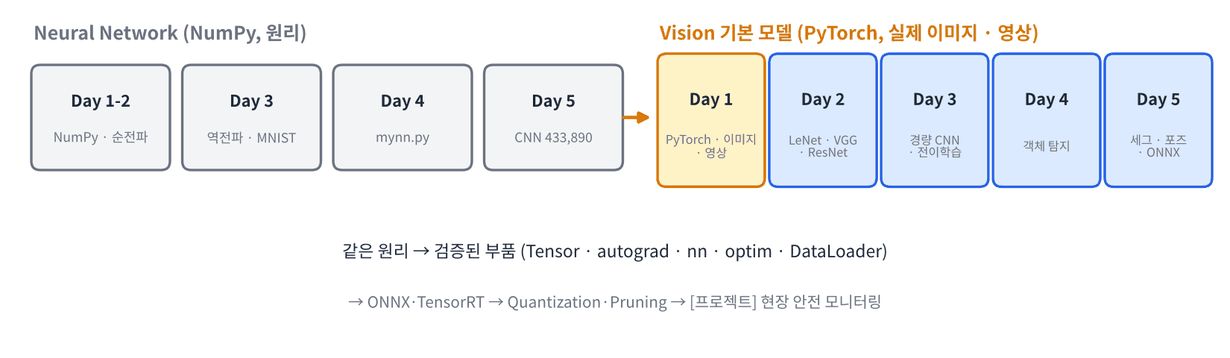

Neural Network 과정에서는 **원리**를 보려고 모든 것을 NumPy 로 직접 만들었습니다. 같은 원리가 PyTorch 에는 이미 빠르고 검증된 부품으로 들어 있습니다. 이번 과정부터는 그 부품을 써서 **더 큰 모델 · 더 많은 데이터 · 실제 이미지와 영상**으로 갑니다. 손으로 만든 경험이 있으니 PyTorch 코드 한 줄 한 줄이 "내가 짰던 그 부분"으로 읽힐 것입니다.

### mynn.py ↔ PyTorch 대응표

| NN 과정 (`mynn.py`, NumPy) | PyTorch | 달라지는 점 |
|---|---|---|
| `np.ndarray` | `torch.Tensor` | GPU 에 올릴 수 있고, 연산 기록(autograd) 을 남길 수 있다 |
| 계층마다 직접 짠 `backward()` | `loss.backward()` 한 줄 | **autograd** 가 계산 그래프를 따라 자동으로 미분 |
| `Affine(784, 100)` | `nn.Linear(784, 100)` | 같은 `Y = XW + b` (PyTorch 는 W 를 (out, in) 으로 저장해 `x @ W.T + b`) |
| `Convolution(1, 30, 5)` | `nn.Conv2d(1, 30, 5)` | im2col · col2im 은 내부에서 처리 (GPU 는 cuDNN) |
| `Pooling(2, 2, 2)` | `nn.MaxPool2d(2)` | 같음 |
| `Relu()` | `nn.ReLU()` | 같음 |
| `SoftmaxWithLoss()` | `nn.CrossEntropyLoss()` | **logits 를 그대로** 넣는다 (softmax 포함) |
| `Sequential([...])` | `nn.Sequential(...)` · `nn.Module` | `parameters()` 로 학습할 값 전체를 모은다 |
| `Adam(lr=0.001)` + `update(params, grads)` | `torch.optim.Adam(model.parameters(), lr=1e-3)` + `step()` | `zero_grad()` 로 기울기를 비우는 단계가 추가 |
| 직접 짠 미니배치 루프 · `rng.permutation` | `DataLoader(..., batch_size=100, shuffle=True)` | 섞기 · 자르기 · 병렬 로딩 |
| `save_params` / `np.savez` | `torch.save(model.state_dict(), path)` | 이름 → 텐서 딕셔너리 |

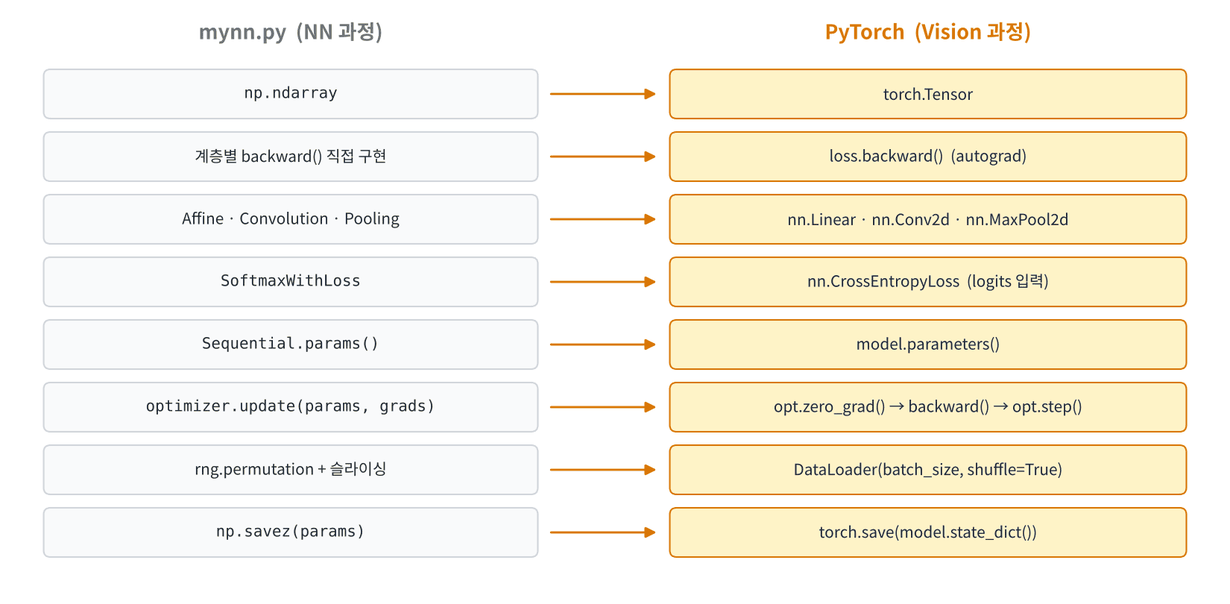

### NN Day 5 의 SimpleConvNet 을 PyTorch 로 다시 쓰기

어제(NN Day 5) NumPy 로 만든 SimpleConvNet 은 이렇게 생겼습니다.

`Conv(1→30, 5×5) → ReLU → Pool(2×2) → Affine(4320→100) → ReLU → Affine(100→10)` — 파라미터 **433,890** 개, 1 epoch test **0.9810**.

PyTorch 로는 계층을 순서대로 늘어놓기만 하면 됩니다. 이미지 텐서의 모양은 NN 과정과 똑같이 **(N, C, H, W)** 입니다.

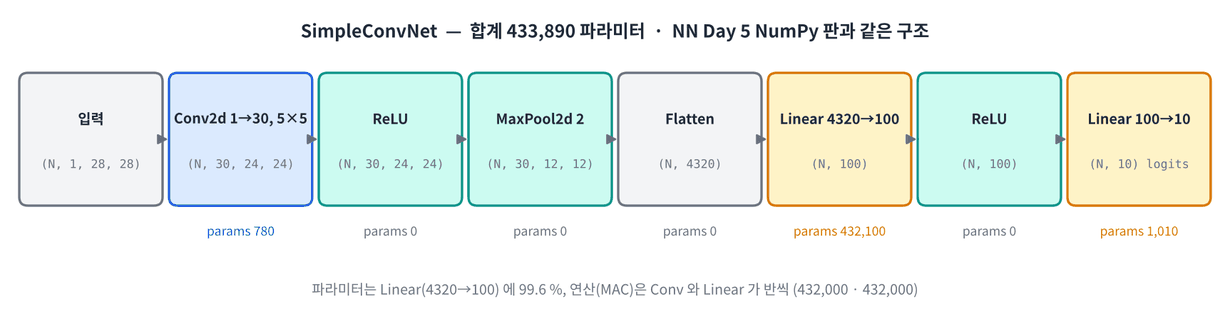

**문제 1-1** NN Day 5 SimpleConvNet 을 `nn.Sequential` 로 만들고 파라미터 수가 **433,890** 인지 확인하세요.

- `nn.Conv2d(in_channels, out_channels, kernel_size)` · `nn.MaxPool2d(kernel_size)` · `nn.Flatten()` · `nn.Linear(in_features, out_features)`
- 파라미터 수는 `p.numel()` (원소 개수) 을 모든 파라미터에 대해 더합니다.

In [ ]:
net = nn.Sequential(
    nn.Conv2d(____, ____, ____),     # (N, 1, 28, 28) → (N, 30, 24, 24)
    nn.ReLU(),
    nn.MaxPool2d(2),              # → (N, 30, 12, 12)
    nn.Flatten(),                 # → (N, 4320)
    nn.Linear(____, 100),
    nn.ReLU(),
    nn.Linear(100, 10),
)
n_params = sum(____ for p in net.parameters())
print(net)
print("파라미터 수:", n_params)

In [ ]:
assert n_params == 433_890; print("✅", f"{n_params:,}")

In [ ]:
#@title 🔒 정답 보기 1-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAxLTEg4pSA4pSACm5ldCA9IG5uLlNlcXVlbnRpYWwoCiAgICBubi5Db252MmQoMSwgMzAs"
    "IDUpLCAgICAgIyAoTiwgMSwgMjgsIDI4KSDihpIgKE4sIDMwLCAyNCwgMjQpCiAgICBubi5SZUxVKCksCiAgICBu"
    "bi5NYXhQb29sMmQoMiksICAgICAgICAgICAgICAjIOKGkiAoTiwgMzAsIDEyLCAxMikKICAgIG5uLkZsYXR0ZW4o"
    "KSwgICAgICAgICAgICAgICAgICMg4oaSIChOLCA0MzIwKQogICAgbm4uTGluZWFyKDQzMjAsIDEwMCksCiAgICBu"
    "bi5SZUxVKCksCiAgICBubi5MaW5lYXIoMTAwLCAxMCksCikKbl9wYXJhbXMgPSBzdW0ocC5udW1lbCgpIGZvciBw"
    "IGluIG5ldC5wYXJhbWV0ZXJzKCkpCnByaW50KG5ldCkKcHJpbnQoIu2MjOudvOuvuO2EsCDsiJg6Iiwgbl9wYXJh"
    "bXMpCgrwn5KhIO2VtOyEpApDb252IDMwwrcxwrc1wrc1ICsgMzAgPSA3ODAsIExpbmVhciA0MzIwwrcxMDAgKyAx"
    "MDAgPSA0MzIsMTAwLCBMaW5lYXIgMTAwwrcxMCArIDEwID0gMSwwMTAg4oaSIDQzMyw4OTAuCk51bVB5IOuhnCDr"
    "p4zrk6Ag66qo64246rO8IO2MjOudvOuvuO2EsCDsiJjqsIAg7KCV7ZmV7Z6IIOqwmeyKteuLiOuLpCDigJQg6rCZ"
    "7J2AIOuqqOuNuOydhCDri6Trpbgg64+E6rWs66GcIOyTtCDqsoPrv5DsnoXri4jri6Qu"
).decode("utf-8"))

**문제 1-2** 계층을 하나씩 통과시키며 shape 를 추적하세요. 가짜 입력 `torch.zeros(2, 1, 28, 28)` (이미지 2장) 을 쓰고, 각 계층 출력의 shape 를 `shapes` 리스트에 모읍니다.

In [ ]:
x = torch.zeros(2, 1, 28, 28)
shapes = []
for layer in net:
    x = ____
    shapes.append(tuple(x.shape))
    print(f"{layer.__class__.__name__:10s} → {tuple(x.shape)}")

In [ ]:
assert shapes == [(2, 30, 24, 24), (2, 30, 24, 24), (2, 30, 12, 12), (2, 4320), (2, 100), (2, 100), (2, 10)]
print("✅")

In [ ]:
#@title 🔒 정답 보기 1-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAxLTIg4pSA4pSACnggPSB0b3JjaC56ZXJvcygyLCAxLCAyOCwgMjgpCnNoYXBlcyA9IFtd"
    "CmZvciBsYXllciBpbiBuZXQ6CiAgICB4ID0gbGF5ZXIoeCkKICAgIHNoYXBlcy5hcHBlbmQodHVwbGUoeC5zaGFw"
    "ZSkpCiAgICBwcmludChmIntsYXllci5fX2NsYXNzX18uX19uYW1lX186MTBzfSDihpIge3R1cGxlKHguc2hhcGUp"
    "fSIpCgrwn5KhIO2VtOyEpApubi5TZXF1ZW50aWFsIOydgCDqs4TsuLXsnYQg7Iic7ISc64yA66GcIOu2gOultOuK"
    "lCDqsoPsnbTrr4DroZwgbmV0KHgpIOyZgCDqsJnsirXri4jri6QuIEZsYXR0ZW4g7J2AIChOLCAzMCwgMTIsIDEy"
    "KSDrpbwgKE4sIDQzMjApIOycvOuhnCDtjrzsuanri4jri6Qg4oCUIE5OIOqzvOyglSBBZmZpbmUg7J2YIHJlc2hh"
    "cGUg7JmAIOqwmeydgCDsnbwu"
).decode("utf-8"))

#### ⚠️ Colab 에서 자주 하는 실수

- **GPU 를 안 켬** — 환경 셀 출력이 `device : cpu` 이면 *런타임 → 런타임 유형 변경 → T4 GPU*. 오늘 실습은 CPU 로도 모두 돌지만 8교시 학습이 몇 배 느립니다.
- **GPU 할당 실패** — 무료 Colab 은 동시 사용자가 많으면 GPU 를 못 받을 수 있습니다. 그대로 CPU 로 진행하세요.
- **런타임 끊김 후 NameError** — 맨 위 환경 셀부터 다시 실행하세요.

#### 📌 1교시 정리

- NN 과정의 부품은 PyTorch 에 모두 있다: Tensor · autograd · nn 계층 · optim · DataLoader.
- 이미지 텐서는 **(N, C, H, W)**. SimpleConvNet = 433,890 파라미터, NumPy 판과 똑같다.
- `nn.CrossEntropyLoss` 는 softmax 를 포함하므로 모델 끝에 softmax 를 붙이지 않는다.

## 2교시 — Tensor · GPU

`torch.Tensor` 는 **ndarray 에 세 가지를 더한 것**입니다.

| 속성 | 뜻 | 확인 |
|---|---|---|
| `shape` · `dtype` | ndarray 와 같음. 단 기본 실수형이 **float32** (NumPy 는 float64) | `t.shape`, `t.dtype` |
| `device` | 데이터가 있는 곳 — `cpu` 또는 `cuda` (GPU 메모리) | `t.device`, `t.to(device)` |
| `requires_grad` | 이 텐서로 한 연산을 기록해 나중에 미분할지 (3교시) | `t.requires_grad` |

> 🎬 **애니메이션** [D1-2 Tensor 의 메모리](https://imguru-mooc.github.io/AI_CAMPUS/VB-day1/animation.html#d1-2)
> 📝 **워크시트** [2교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/VB-day1/worksheet.html#t2)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

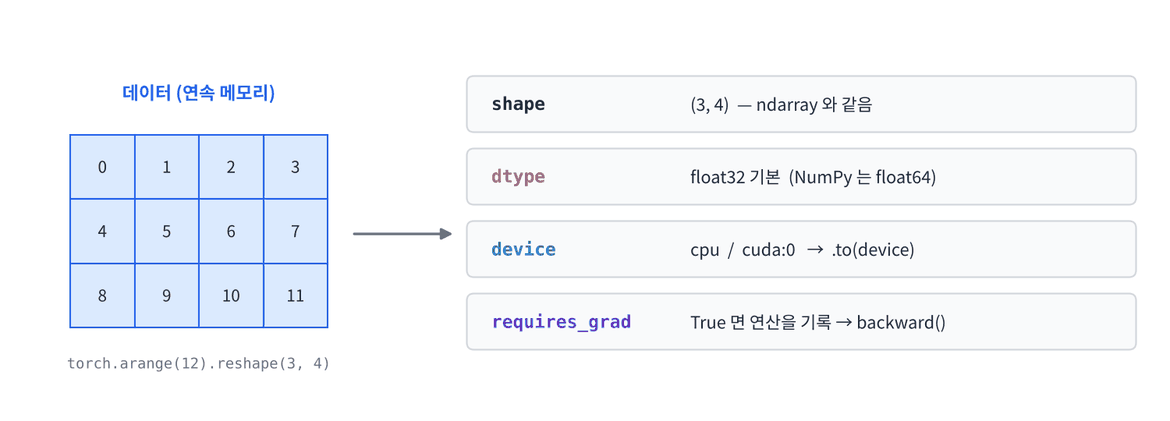

NumPy 와 거의 같은 함수 이름을 씁니다: `torch.zeros` · `torch.arange` · `reshape` · `sum(dim=...)` · `@`. 다른 점은 축 인자 이름이 `axis` 대신 **`dim`** 이라는 것 정도입니다 (`axis` 도 대부분 받아 줍니다).

In [ ]:
a = np.array([[1.0, 2.0], [3.0, 4.0]])
t = torch.tensor([[1.0, 2.0], [3.0, 4.0]])
print("NumPy :", a.dtype, a.shape)
print("Torch :", t.dtype, t.shape, t.device)
print("합 (dim=0):", t.sum(dim=0), "| 행렬곱:\n", t @ t)
print("ndarray 로:", type(t.numpy()), "| 파이썬 숫자로:", t[0, 1].item())

**문제 2-1** dtype 함정 — NumPy 배열은 기본이 **float64** 라서 그대로 텐서로 바꾸면 float64 텐서가 됩니다. 모델 가중치는 float32 이므로 `RuntimeError: expected ... Float but found Double` 이 납니다. NumPy 데이터를 **float32 텐서**로 바꾸세요.

In [ ]:
X_np = rng.standard_normal((4, 784))          # float64
X = torch.from_numpy(X_np).____
layer = nn.Linear(784, 10)
Y = layer(X)

In [ ]:
assert X.dtype == torch.float32 and Y.shape == (4, 10); print("✅", X.dtype, tuple(Y.shape))

In [ ]:
#@title 🔒 정답 보기 2-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTEg4pSA4pSAClhfbnAgPSBybmcuc3RhbmRhcmRfbm9ybWFsKCg0LCA3ODQpKSAgICAg"
    "ICAgICAjIGZsb2F0NjQKWCA9IHRvcmNoLmZyb21fbnVtcHkoWF9ucCkuZmxvYXQoKQpsYXllciA9IG5uLkxpbmVh"
    "cig3ODQsIDEwKQpZID0gbGF5ZXIoWCkKCvCfkqEg7ZW07ISkCi5mbG9hdCgpIOydgCAudG8odG9yY2guZmxvYXQz"
    "Mikg7JmAIOqwmeyKteuLiOuLpC4g67CY64yA66GcIOygleyImCDroIjsnbTruJTsnYAgbm4uQ3Jvc3NFbnRyb3B5"
    "TG9zcyDqsIAgbG9uZyhpbnQ2NCkg7J2EIOyalOq1rO2VqeuLiOuLpCDigJQgNOq1kOyLnC4="
).decode("utf-8"))

### `from_numpy` 는 메모리를 공유하고, `torch.tensor` 는 복사한다

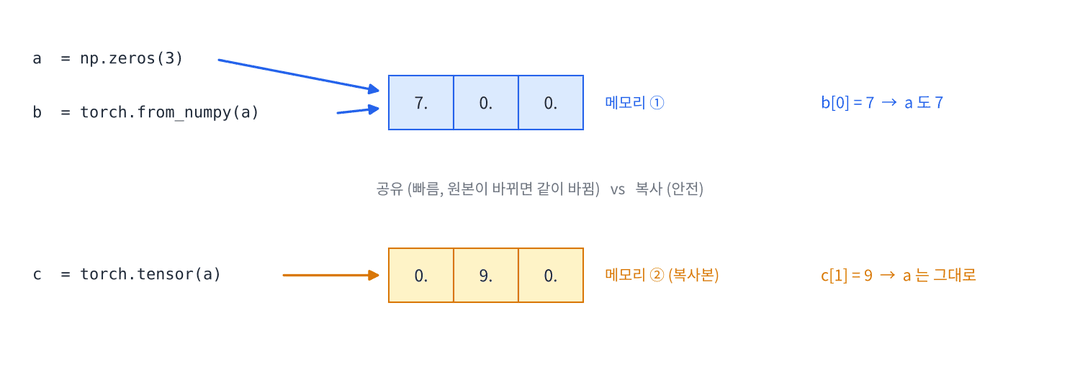

NN 과정 Day 1 의 "`b = a` 는 복사가 아니다" 와 같은 이야기입니다. `torch.from_numpy(a)` 는 **같은 메모리**를 텐서로 보이게 할 뿐이라 빠르지만, 한쪽을 고치면 다른 쪽도 바뀝니다. `torch.tensor(a)` 는 새 메모리에 **복사**합니다.

**문제 2-2** 아래 코드를 실행한 뒤 `a` 와 `c` 는 각각 어떤 값일까요? **실행하기 전에 예측**해서 리스트로 쓰세요.

In [ ]:
a = np.zeros(3)
b = torch.from_numpy(a)       # 공유
c = torch.tensor(a)           # 복사
b[0] = 7.0
c[1] = 9.0
answer_a = ____
answer_c = ____

In [ ]:
assert a.tolist() == answer_a and c.tolist() == answer_c; print("✅ a =", a, "| c =", c)

In [ ]:
#@title 🔒 정답 보기 2-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTIg4pSA4pSACmEgPSBucC56ZXJvcygzKQpiID0gdG9yY2guZnJvbV9udW1weShhKSAg"
    "ICAgICAjIOqzteycoApjID0gdG9yY2gudGVuc29yKGEpICAgICAgICAgICAjIOuzteyCrApiWzBdID0gNy4wCmNb"
    "MV0gPSA5LjAKYW5zd2VyX2EgPSBbNy4wLCAwLjAsIDAuMF0KYW5zd2VyX2MgPSBbMC4wLCA5LjAsIDAuMF0KCvCf"
    "kqEg7ZW07ISkCmIg64qUIGEg7JmAIOqwmeydgCDrqZTrqqjrpqzrnbwgYlswXSA9IDcg7J20IGEg7JeQIOuztOye"
    "heuLiOuLpC4gYyDripQg66eM65OkIOuVjCDrs7XsgqztlojsnLzrr4DroZwgY1sxXSA9IDkg64qUIGEg7JeQIOyY"
    "ge2WpeydtCDsl4bqs6AsIOq3uCDrkqQgYiDsnZgg67OA6rK964+EIGMg7JeQIOuztOydtOyngCDslYrsirXri4jr"
    "i6QuCk51bVB5IOuhnCDsoITsspjrpqztlZwg67Cw7Je07J2EIGZyb21fbnVtcHkg66GcIOuwlOq+vCDrkqQg7JuQ"
    "67O4IOuwsOyXtOydhCDsnqzsgqzsmqntlZjrqbQg7YWQ7IScIOqwkuydtCDrqrDrnpgg67CU64CUIOyImCDsnojs"
    "irXri4jri6Qu"
).decode("utf-8"))

### NumPy 코드를 PyTorch 로 옮기기 — `Y = XW + b` 와 softmax

NN 과정 Day 2 의 순전파를 그대로 옮겨 봅니다. 함수 이름만 바뀝니다: `np.exp → torch.exp`, `axis → dim`, `keepdims → keepdim`.

**문제 2-3** NumPy 순전파를 PyTorch 로 옮기고 두 결과가 같은지 확인하세요. softmax 는 overflow 를 막기 위해 행마다 최댓값을 뺍니다.

In [ ]:
def forward_np(X, W, b):
    Y = X @ W + b
    Y = Y - Y.max(axis=1, keepdims=True)
    e = np.exp(Y)
    return e / e.sum(axis=1, keepdims=True)

def forward_torch(X, W, b):
    Y = X @ W + b
    Y = Y - Y.max(____, keepdim=True).values
    e = torch.____(Y)
    return e / e.sum(dim=1, keepdim=____)

Xn, Wn, bn = rng.standard_normal((5, 3)), rng.standard_normal((3, 4)), rng.standard_normal(4)
P_np = forward_np(Xn, Wn, bn)
P_t = forward_torch(torch.from_numpy(Xn), torch.from_numpy(Wn), torch.from_numpy(bn))

In [ ]:
assert np.allclose(P_np, P_t.numpy()) and torch.allclose(P_t, torch.softmax(torch.from_numpy(Xn @ Wn + bn), dim=1))
print("✅ 행 합:", P_t.sum(dim=1))

In [ ]:
#@title 🔒 정답 보기 2-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTMg4pSA4pSACmRlZiBmb3J3YXJkX25wKFgsIFcsIGIpOgogICAgWSA9IFggQCBXICsg"
    "YgogICAgWSA9IFkgLSBZLm1heChheGlzPTEsIGtlZXBkaW1zPVRydWUpCiAgICBlID0gbnAuZXhwKFkpCiAgICBy"
    "ZXR1cm4gZSAvIGUuc3VtKGF4aXM9MSwga2VlcGRpbXM9VHJ1ZSkKCmRlZiBmb3J3YXJkX3RvcmNoKFgsIFcsIGIp"
    "OgogICAgWSA9IFggQCBXICsgYgogICAgWSA9IFkgLSBZLm1heChkaW09MSwga2VlcGRpbT1UcnVlKS52YWx1ZXMK"
    "ICAgIGUgPSB0b3JjaC5leHAoWSkKICAgIHJldHVybiBlIC8gZS5zdW0oZGltPTEsIGtlZXBkaW09VHJ1ZSkKClhu"
    "LCBXbiwgYm4gPSBybmcuc3RhbmRhcmRfbm9ybWFsKCg1LCAzKSksIHJuZy5zdGFuZGFyZF9ub3JtYWwoKDMsIDQp"
    "KSwgcm5nLnN0YW5kYXJkX25vcm1hbCg0KQpQX25wID0gZm9yd2FyZF9ucChYbiwgV24sIGJuKQpQX3QgPSBmb3J3"
    "YXJkX3RvcmNoKHRvcmNoLmZyb21fbnVtcHkoWG4pLCB0b3JjaC5mcm9tX251bXB5KFduKSwgdG9yY2guZnJvbV9u"
    "dW1weShibikpCgrwn5KhIO2VtOyEpAp0b3JjaCDsnZggbWF4KGRpbT0uLi4pIOuKlCAodmFsdWVzLCBpbmRpY2Vz"
    "KSDrkZAg6rCc66W8IOuPjOugpOyjvOuvgOuhnCAudmFsdWVzIOulvCDslIHri4jri6QuIOyLpOygnOuhnOuKlCB0"
    "b3JjaC5zb2Z0bWF4KFksIGRpbT0xKSDtlZwg7KSE7J2066m0IOuQmOqzoCwgb3ZlcmZsb3cg7LKY66as64+EIOuT"
    "pOyWtCDsnojsirXri4jri6Qu"
).decode("utf-8"))

### shape 바꾸기 — `reshape` · `view` · `permute` · `unsqueeze`

| 함수 | 하는 일 | 쓰는 곳 |
|---|---|---|
| `reshape(2, 12)` · `view(2, 12)` | 원소 순서는 그대로, 모양만 바꿈 | Flatten |
| `permute(2, 0, 1)` | **축의 순서**를 바꿈 (원소 배치가 달라짐) | 이미지 HWC → CHW (6교시) |
| `unsqueeze(0)` · `squeeze(0)` | 크기 1 인 축을 넣기 · 빼기 | 이미지 1장 → 배치 (1, C, H, W) |

**문제 2-4** shape (2, 3, 4) 텐서에서 원하는 모양을 만드세요.

1. `p` : 마지막 두 축을 바꾼 (2, 4, 3)
2. `u` : 맨 앞에 크기 1 인 축을 넣은 (1, 2, 3, 4)
3. `f` : 첫 축만 남기고 펼친 (2, 12)

In [ ]:
x = torch.arange(24).reshape(2, 3, 4)
p = x.permute(____)
u = x.____
f = x.reshape(2, ____)

In [ ]:
assert p.shape == (2, 4, 3) and u.shape == (1, 2, 3, 4) and f.shape == (2, 12)
assert p[1, 3, 2] == x[1, 2, 3]
print("✅", tuple(p.shape), tuple(u.shape), tuple(f.shape))

In [ ]:
#@title 🔒 정답 보기 2-4 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTQg4pSA4pSACnggPSB0b3JjaC5hcmFuZ2UoMjQpLnJlc2hhcGUoMiwgMywgNCkKcCA9"
    "IHgucGVybXV0ZSgwLCAyLCAxKQp1ID0geC51bnNxdWVlemUoMCkKZiA9IHgucmVzaGFwZSgyLCAtMSkKCvCfkqEg"
    "7ZW07ISkCnBlcm11dGUg64qUICfsg4ggMOuyiCDstpUgPSDsmJsgMOuyiCwg7IOIIDHrsoggPSDsmJsgMuuyiCwg"
    "7IOIIDLrsoggPSDsmJsgMeuyiCcuIOq3uOuemOyEnCBwWzEsIDMsIDJdID09IHhbMSwgMiwgM10uIC0xIOydgCAn"
    "64KY66i47KeA64qUIOyVjOyVhOyEnCDqs4TsgrAnLg=="
).decode("utf-8"))

### GPU 로 옮기기 — `.to(device)`

GPU 는 수천 개의 코어로 행렬곱을 한꺼번에 계산합니다. 데이터와 모델이 **같은 device** 에 있어야 계산할 수 있습니다. 섞이면 `Expected all tensors to be on the same device` 오류가 납니다.

In [ ]:
def bench(dev, n=2048, reps=10):
    A = torch.randn(n, n, device=dev); B = torch.randn(n, n, device=dev)
    A @ B                                   # 준비 운동 (첫 실행은 초기화 시간이 섞임)
    if dev.type == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(reps):
        C = A @ B
    if dev.type == "cuda": torch.cuda.synchronize()   # GPU 는 비동기 — 끝날 때까지 기다려야 정확
    return (time.perf_counter() - t0) / reps * 1000

cpu_ms = bench(torch.device("cpu"))
print(f"CPU  {cpu_ms:8.2f} ms / 2048×2048 행렬곱")
if device.type == "cuda":
    gpu_ms = bench(device)
    print(f"GPU  {gpu_ms:8.2f} ms  →  약 {cpu_ms / gpu_ms:.0f}배 빠름")

#### ⚠️ 자주 하는 실수

- `torch.from_numpy(float64 배열)` 을 그대로 모델에 넣음 → `.float()` 로 float32.
- 모델은 GPU, 데이터는 CPU → 둘 다 `.to(device)`.
- GPU 시간을 `synchronize()` 없이 재면 실제보다 훨씬 빠르게 나옵니다 (GPU 는 명령만 받고 바로 돌아옴).
- GPU 텐서는 바로 `.numpy()` 가 안 됩니다 → `.cpu().numpy()`.

#### 📌 2교시 정리

- Tensor = ndarray + device + requires_grad. 기본 실수형은 float32, 축 인자는 `dim`.
- `from_numpy` 는 공유, `torch.tensor` 는 복사.
- `permute` 는 축 순서, `reshape/view` 는 모양, `unsqueeze` 는 배치 축.

## 3교시 — autograd: 역전파를 자동으로

NN 과정 Day 3 에서는 계층마다 `backward()` 를 손으로 짜고, gradient check 로 맞는지 확인했습니다. PyTorch 는 `requires_grad=True` 인 텐서로 한 연산을 모두 **계산 그래프**로 기록해 두었다가, `loss.backward()` 한 번에 연쇄 법칙을 거꾸로 적용합니다.

> 🎬 **애니메이션** [D1-3 autograd 계산 그래프](https://imguru-mooc.github.io/AI_CAMPUS/VB-day1/animation.html#d1-3)
> 📝 **워크시트** [3교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/VB-day1/worksheet.html#t3)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

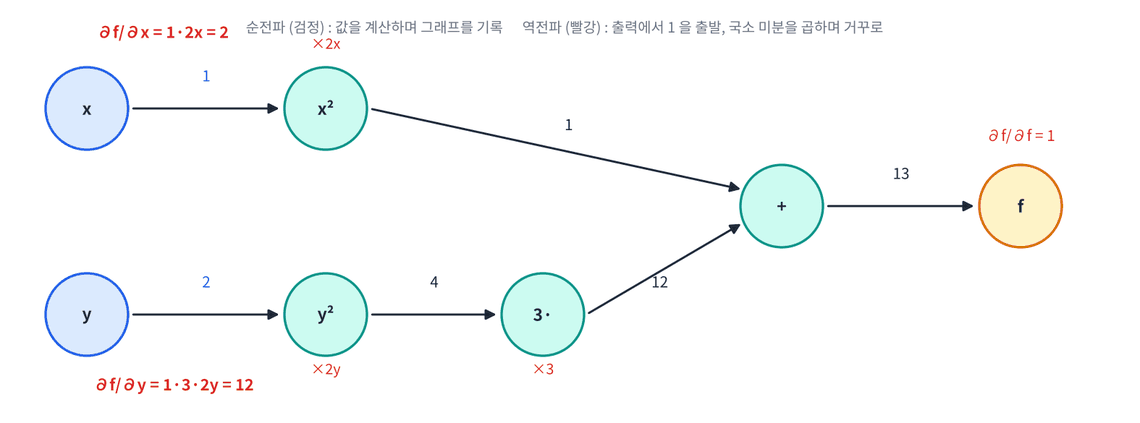

순전파 때 각 노드는 "나중에 미분할 때 필요한 값" 을 저장해 둡니다 (NN 과정의 `self.x`, `self.mask` 와 같은 일). `backward()` 는 출력에서 1 을 출발시켜 노드마다 **국소 미분을 곱하며** 입력 쪽으로 내려갑니다. 결과는 각 잎(leaf) 텐서의 `.grad` 에 **더해집니다**.

**문제 3-1** NN 과정 Day 1 의 함수 $f(x, y) = x^2 + 3y^2$ 를 (1, 2) 에서 미분하세요. 손으로 하면 $\nabla f = (2x, 6y) = (2, 12)$.

In [ ]:
x = torch.tensor(1.0, requires_grad=____)
y = torch.tensor(2.0, requires_grad=True)
f = x ** 2 + 3 * y ** 2
f.____
print("f =", f.item(), "| df/dx =", x.grad.item(), "| df/dy =", y.grad.item())

In [ ]:
assert f.item() == 13.0 and x.grad.item() == 2.0 and y.grad.item() == 12.0; print("✅")

In [ ]:
#@title 🔒 정답 보기 3-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAzLTEg4pSA4pSACnggPSB0b3JjaC50ZW5zb3IoMS4wLCByZXF1aXJlc19ncmFkPVRydWUp"
    "CnkgPSB0b3JjaC50ZW5zb3IoMi4wLCByZXF1aXJlc19ncmFkPVRydWUpCmYgPSB4ICoqIDIgKyAzICogeSAqKiAy"
    "CmYuYmFja3dhcmQoKQpwcmludCgiZiA9IiwgZi5pdGVtKCksICJ8IGRmL2R4ID0iLCB4LmdyYWQuaXRlbSgpLCAi"
    "fCBkZi9keSA9IiwgeS5ncmFkLml0ZW0oKSkKCvCfkqEg7ZW07ISkCmYg64qUIOyKpOy5vOudvCjsm5DshowgMeqw"
    "nCkg65287IScIGYuYmFja3dhcmQoKSDrpbwg67CU66GcIOu2gOulvCDsiJgg7J6I7Iq164uI64ukLiDshpDsi6Qo"
    "bG9zcykg64+EIOyWuOygnOuCmCDsiqTsubzrnbzsnoXri4jri6Qu"
).decode("utf-8"))

**문제 3-2** 기울기는 **누적**됩니다. `backward()` 를 두 번 부르면 `.grad` 가 두 배가 됩니다. 두 번째 `backward()` 전에 기울기를 비워 `x.grad` 가 2 가 되도록 하세요.

(같은 그래프를 두 번 미분하려면 `retain_graph=True` 가 필요해서 여기서는 f 를 다시 계산합니다.)

In [ ]:
x = torch.tensor(1.0, requires_grad=True)
(x ** 2).backward()
print("1번째:", x.grad.item())
(x ** 2).backward()
print("비우지 않고 2번째:", x.grad.item())      # 4.0 — 더해졌다
x.grad.____
(x ** 2).backward()
print("비우고 3번째:", x.grad.item())

In [ ]:
assert x.grad.item() == 2.0; print("✅")

In [ ]:
#@title 🔒 정답 보기 3-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAzLTIg4pSA4pSACnggPSB0b3JjaC50ZW5zb3IoMS4wLCByZXF1aXJlc19ncmFkPVRydWUp"
    "Cih4ICoqIDIpLmJhY2t3YXJkKCkKcHJpbnQoIjHrsojsp7g6IiwgeC5ncmFkLml0ZW0oKSkKKHggKiogMikuYmFj"
    "a3dhcmQoKQpwcmludCgi67mE7Jqw7KeAIOyViuqzoCAy67KI7Ke4OiIsIHguZ3JhZC5pdGVtKCkpICAgICAgIyA0"
    "LjAg4oCUIOuNlO2VtOyhjOuLpAp4LmdyYWQuemVyb18oKQooeCAqKiAyKS5iYWNrd2FyZCgpCnByaW50KCLruYTs"
    "mrDqs6AgM+uyiOynuDoiLCB4LmdyYWQuaXRlbSgpKQoK8J+SoSDtlbTshKQK64iE7KCB7J2AIOuyhOq3uOqwgCDs"
    "lYTri4jrnbwg6riw64ql7J6F64uI64ukICjtgbAg67Cw7LmY66W8IOyXrOufrCDrsojsl5Ag64KY64igIOq4sOya"
    "uOq4sOulvCDrqqjsnYQg65WMIOyUgCkuIOq3uOuemOyEnCDtlZnsirUg66Oo7ZSE64qUIOunpCBzdGVwIG9wdGlt"
    "aXplci56ZXJvX2dyYWQoKSDroZwg7Iuc7J6R7ZWp64uI64ukIOKAlCA16rWQ7IucLg=="
).decode("utf-8"))

### autograd 와 내가 만든 역전파 비교 — Affine + Softmax + Cross-Entropy

NN 과정 Day 3 에서 유도한 식: Softmax-with-Loss 의 역전파는 **(y − t) / N**, Affine 의 가중치 기울기는 **dW = Xᵀ · dY**. 즉 $\frac{\partial L}{\partial W} = X^T (y - t) / N$ — "(y − t) x" 형태입니다. autograd 결과와 비교해 봅시다.

**문제 3-3** 손으로 유도한 기울기 `dW_manual`, `db_manual` 을 완성하고 autograd 의 `W.grad`, `b.grad` 와 같은지 확인하세요. `T` 는 one-hot 정답입니다.

In [ ]:
N, D, K = 6, 4, 3
X = torch.randn(N, D)
t = torch.tensor([0, 2, 1, 2, 0, 1])
T = F.one_hot(t, K).float()
W = torch.randn(D, K, requires_grad=True)
b = torch.zeros(K, requires_grad=True)

logits = X @ W + b                       # Y = XW + b
loss = F.cross_entropy(logits, t)        # softmax + cross-entropy + 평균
loss.backward()

Y = torch.softmax(logits, dim=1).detach()   # detach: 그래프에서 떼어 낸 값만
dW_manual = X.T @ (____) / N
db_manual = (____).sum(dim=0) / N

In [ ]:
assert torch.allclose(dW_manual, W.grad, atol=1e-6) and torch.allclose(db_manual, b.grad, atol=1e-6)
print("✅ 최대 오차:", (dW_manual - W.grad).abs().max().item())

In [ ]:
#@title 🔒 정답 보기 3-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAzLTMg4pSA4pSACk4sIEQsIEsgPSA2LCA0LCAzClggPSB0b3JjaC5yYW5kbihOLCBEKQp0"
    "ID0gdG9yY2gudGVuc29yKFswLCAyLCAxLCAyLCAwLCAxXSkKVCA9IEYub25lX2hvdCh0LCBLKS5mbG9hdCgpClcg"
    "PSB0b3JjaC5yYW5kbihELCBLLCByZXF1aXJlc19ncmFkPVRydWUpCmIgPSB0b3JjaC56ZXJvcyhLLCByZXF1aXJl"
    "c19ncmFkPVRydWUpCgpsb2dpdHMgPSBYIEAgVyArIGIgICAgICAgICAgICAgICAgICAgICAgICMgWSA9IFhXICsg"
    "Ygpsb3NzID0gRi5jcm9zc19lbnRyb3B5KGxvZ2l0cywgdCkgICAgICAgICMgc29mdG1heCArIGNyb3NzLWVudHJv"
    "cHkgKyDtj4nqt6AKbG9zcy5iYWNrd2FyZCgpCgpZID0gdG9yY2guc29mdG1heChsb2dpdHMsIGRpbT0xKS5kZXRh"
    "Y2goKSAgICMgZGV0YWNoOiDqt7jrnpjtlITsl5DshJwg65a87Ja0IOuCuCDqsJLrp4wKZFdfbWFudWFsID0gWC5U"
    "IEAgKFkgLSBUKSAvIE4KZGJfbWFudWFsID0gKFkgLSBUKS5zdW0oZGltPTApIC8gTgoK8J+SoSDtlbTshKQKTk4g"
    "6rO87KCV7JeQ7IScIGdyYWRpZW50IGNoZWNrIOuhnCDtmZXsnbjtlZjrjZgg7J287J2EIOuwmOuMgOuhnCDtlZwg"
    "6rKD7J6F64uI64ukOiDsnbTsoJzripQgYXV0b2dyYWQg6rCAIOq4sOykgOydtOqzoCwg64K0IOycoOuPhOqwgCDr"
    "p57ripTsp4Ag64yA7KGw7ZWp64uI64ukLiBGLmNyb3NzX2VudHJvcHkg64qUIO2Pieq3oOydhCDrgrTrr4DroZwg"
    "L04g7J20IOuTpOyWtOqwkeuLiOuLpC4="
).decode("utf-8"))

**문제 3-4** autograd 로 **경사하강법**을 돌려 보세요 (NN Day 1 8교시와 같은 문제: 출발 (−4, 2), 학습률 0.1, 100 step).

- 갱신은 기록할 필요가 없는 연산이므로 `torch.no_grad()` 안에서 합니다.
- 갱신 뒤에는 기울기를 비웁니다.

In [ ]:
p = torch.tensor([-4.0, 2.0], requires_grad=True)
lr = 0.1
for step in range(100):
    loss = p[0] ** 2 + 3 * p[1] ** 2
    loss.backward()
    with torch.____():
        p -= ____
    p.grad.____
print("끝 위치:", p.detach().numpy(), "| f =", loss.item())

In [ ]:
assert p.detach().norm() < 1e-3; print("✅")

In [ ]:
#@title 🔒 정답 보기 3-4 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAzLTQg4pSA4pSACnAgPSB0b3JjaC50ZW5zb3IoWy00LjAsIDIuMF0sIHJlcXVpcmVzX2dy"
    "YWQ9VHJ1ZSkKbHIgPSAwLjEKZm9yIHN0ZXAgaW4gcmFuZ2UoMTAwKToKICAgIGxvc3MgPSBwWzBdICoqIDIgKyAz"
    "ICogcFsxXSAqKiAyCiAgICBsb3NzLmJhY2t3YXJkKCkKICAgIHdpdGggdG9yY2gubm9fZ3JhZCgpOgogICAgICAg"
    "IHAgLT0gbHIgKiBwLmdyYWQKICAgIHAuZ3JhZC56ZXJvXygpCnByaW50KCLrgZ0g7JyE7LmYOiIsIHAuZGV0YWNo"
    "KCkubnVtcHkoKSwgInwgZiA9IiwgbG9zcy5pdGVtKCkpCgrwn5KhIO2VtOyEpApub19ncmFkIOyXhuydtCBwIC09"
    "IC4uLiDrpbwg7ZWY66m0ICdhIGxlYWYgVmFyaWFibGUgdGhhdCByZXF1aXJlcyBncmFkIGlzIGJlaW5nIHVzZWQg"
    "aW4gYW4gaW4tcGxhY2Ugb3BlcmF0aW9uJyDsmKTrpZjqsIAg64Kp64uI64ukLiDqsLHsi6DquYzsp4Ag6re4656Y"
    "7ZSE7JeQIOuEo+ycvOuptCDslYgg65CY6riwIOuVjOusuOyeheuLiOuLpC4="
).decode("utf-8"))

**문제 3-5** 같은 일을 `torch.optim.SGD` 로 하세요. 옵티마이저가 갱신(`step`) 과 비우기(`zero_grad`) 를 대신합니다. 세 줄의 **순서**가 핵심입니다.

In [ ]:
q = torch.tensor([-4.0, 2.0], requires_grad=True)
opt = torch.optim.SGD([q], lr=0.1)
for step in range(100):
    loss = q[0] ** 2 + 3 * q[1] ** 2
    opt.____
    loss.____
    opt.____

In [ ]:
assert torch.allclose(p, q); print("✅ 문제 3-4 와 같은 결과:", q.detach().numpy())

In [ ]:
#@title 🔒 정답 보기 3-5 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAzLTUg4pSA4pSACnEgPSB0b3JjaC50ZW5zb3IoWy00LjAsIDIuMF0sIHJlcXVpcmVzX2dy"
    "YWQ9VHJ1ZSkKb3B0ID0gdG9yY2gub3B0aW0uU0dEKFtxXSwgbHI9MC4xKQpmb3Igc3RlcCBpbiByYW5nZSgxMDAp"
    "OgogICAgbG9zcyA9IHFbMF0gKiogMiArIDMgKiBxWzFdICoqIDIKICAgIG9wdC56ZXJvX2dyYWQoKQogICAgbG9z"
    "cy5iYWNrd2FyZCgpCiAgICBvcHQuc3RlcCgpCgrwn5KhIO2VtOyEpAp6ZXJvX2dyYWQg4oaSIGJhY2t3YXJkIOKG"
    "kiBzdGVwLiBOTiDqs7zsoJXsnZggb3B0aW1pemVyLnVwZGF0ZShwYXJhbXMsIGdyYWRzKSDqsIAgc3RlcCgpIOyc"
    "vOuhnCwgZ3JhZHMg65SV7IWU64SI66as6rCAIOqwgSDtjIzrnbzrr7jthLDsnZggLmdyYWQg66GcIOuwlOuAjOyX"
    "iOyKteuLiOuLpC4="
).decode("utf-8"))

#### ⚠️ 자주 하는 실수

- `zero_grad()` 를 빼먹음 → 기울기가 계속 더해져 학습이 폭주합니다.
- 그래프가 붙은 텐서를 그대로 `.numpy()` → `Can't call numpy() on Tensor that requires grad`. `.detach().numpy()` 를 쓰세요.
- 평가 · 추론에서 기록을 안 끔 → 메모리 낭비. `with torch.no_grad():` 로 감쌉니다.

#### 📌 3교시 정리

- `requires_grad=True` → 연산 기록 → `backward()` → `.grad` 에 **누적**.
- autograd 의 결과는 손으로 유도한 `Xᵀ(y − t)/N` 과 같다.
- 학습 한 step = `zero_grad()` → `backward()` → `step()`.

## 4교시 — nn.Module · Dataset · DataLoader

### 모델은 `nn.Module` 을 상속한 클래스

`__init__` 에서 계층을 **만들고**, `forward` 에서 데이터가 지나가는 길을 **쓴다**. `self.` 에 붙인 계층의 파라미터는 `model.parameters()` 로 자동으로 모입니다 — NN 과정 `Sequential.params()` 와 같은 일.

> 🎬 **애니메이션** [D1-4 Dataset · DataLoader](https://imguru-mooc.github.io/AI_CAMPUS/VB-day1/animation.html#d1-4)
> 📝 **워크시트** [4교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/VB-day1/worksheet.html#t4)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

**문제 4-1** NN 과정 Day 3 의 **784-100-10** 신경망을 `nn.Module` 로 만들고 파라미터 수가 79,510 인지 확인하세요.

In [ ]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(____, ____)
        self.fc2 = nn.Linear(100, 10)

    def forward(self, x):
        x = x.flatten(____)               # (N, 1, 28, 28) → (N, 784), 배치 축은 남긴다
        x = F.relu(self.fc1(x))
        return ____             # logits — softmax 는 손실 함수 안에서

mlp = MLP()
n = sum(p.numel() for p in mlp.parameters())
print(mlp, "\n파라미터 수:", n)

In [ ]:
assert n == 79_510 and mlp(torch.zeros(3, 1, 28, 28)).shape == (3, 10); print("✅")

In [ ]:
#@title 🔒 정답 보기 4-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTEg4pSA4pSACmNsYXNzIE1MUChubi5Nb2R1bGUpOgogICAgZGVmIF9faW5pdF9fKHNl"
    "bGYpOgogICAgICAgIHN1cGVyKCkuX19pbml0X18oKQogICAgICAgIHNlbGYuZmMxID0gbm4uTGluZWFyKDc4NCwg"
    "MTAwKQogICAgICAgIHNlbGYuZmMyID0gbm4uTGluZWFyKDEwMCwgMTApCgogICAgZGVmIGZvcndhcmQoc2VsZiwg"
    "eCk6CiAgICAgICAgeCA9IHguZmxhdHRlbigxKSAgICAgICAgICAgICAgICMgKE4sIDEsIDI4LCAyOCkg4oaSIChO"
    "LCA3ODQpLCDrsLDsuZgg7LaV7J2AIOuCqOq4tOuLpAogICAgICAgIHggPSBGLnJlbHUoc2VsZi5mYzEoeCkpCiAg"
    "ICAgICAgcmV0dXJuIHNlbGYuZmMyKHgpICAgICAgICAgICAgICMgbG9naXRzIOKAlCBzb2Z0bWF4IOuKlCDshpDs"
    "i6Qg7ZWo7IiYIOyViOyXkOyEnAoKbWxwID0gTUxQKCkKbiA9IHN1bShwLm51bWVsKCkgZm9yIHAgaW4gbWxwLnBh"
    "cmFtZXRlcnMoKSkKcHJpbnQobWxwLCAiXG7tjIzrnbzrr7jthLAg7IiYOiIsIG4pCgrwn5KhIO2VtOyEpAo3ODTC"
    "tzEwMCArIDEwMCArIDEwMMK3MTAgKyAxMCA9IDc5LDUxMCDigJQgTk4gRGF5IDMg6rO8IOqwmeydgCDsiKvsnpDs"
    "noXri4jri6QuIGZsYXR0ZW4oMSkg7J2AIDHrsogg7LaV67aA7YSwIOuBneq5jOyngCDtjrzsuanri4jri6QgKDDr"
    "soggPSDrsLDsuZgpLg=="
).decode("utf-8"))

### 데이터는 `Dataset` → `DataLoader`

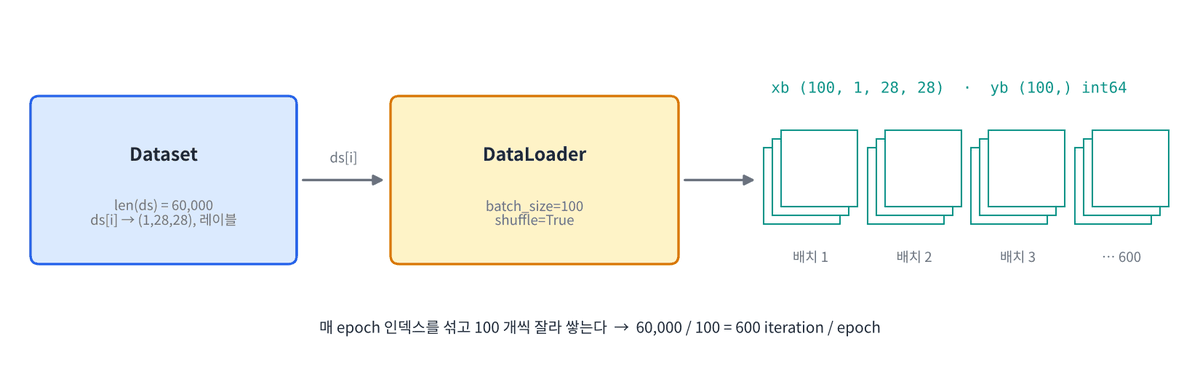

- **Dataset** : `len(ds)` 와 `ds[i]` 만 알면 되는 객체. i 번째 (이미지, 레이블) 한 쌍을 돌려준다.
- **DataLoader** : Dataset 에서 인덱스를 섞고(`shuffle=True`), `batch_size` 개씩 모아 **텐서 하나로 쌓아** 준다. NN 과정 Day 3 에서 `rng.permutation(N)` 으로 짰던 미니배치 루프입니다.
- `torchvision.datasets.MNIST` 는 Dataset 이 이미 만들어져 있는 것이고, `transforms.ToTensor()` 가 uint8 (28, 28) 이미지를 float (1, 28, 28) · 0~1 로 바꿉니다.

In [ ]:
to_tensor = transforms.ToTensor()
train_set = datasets.MNIST("data", train=True, download=True, transform=to_tensor)
test_set = datasets.MNIST("data", train=False, download=True, transform=to_tensor)
img, label = train_set[0]
print(len(train_set), len(test_set), "| 한 장:", tuple(img.shape), img.dtype, f"{img.min():.1f}~{img.max():.1f}", "| 레이블:", label)

fig, ax = plt.subplots(1, 8, figsize=(12, 2))
for i in range(8):
    ax[i].imshow(train_set[i][0][0], cmap="gray"); ax[i].set_title(train_set[i][1]); ax[i].axis("off")
plt.show()

**문제 4-2** NumPy 배열에서 Dataset 을 직접 만들어 보세요. 나중에 우리가 모은 사진 · 영상 프레임도 이렇게 Dataset 으로 만듭니다.

- `X` 는 uint8 (N, 28, 28), `y` 는 정수 (N,)
- `__getitem__` 은 (float32 텐서 (1, 28, 28) 0~1, 정수 레이블) 을 돌려준다.

In [ ]:
class NumpyDigits(Dataset):
    def __init__(self, X, y):
        self.X, self.y = X, y

    def __len__(self):
        return ____

    def __getitem__(self, i):
        x = torch.from_numpy(self.X[i]).float() / ____
        return x.____, int(self.y[i])

X_small = test_set.data[:500].numpy()          # uint8 (500, 28, 28)
y_small = test_set.targets[:500].numpy()
small = NumpyDigits(X_small, y_small)
x0, y0 = small[0]

In [ ]:
assert len(small) == 500 and x0.shape == (1, 28, 28) and x0.dtype == torch.float32 and 0 <= x0.min() and x0.max() <= 1
assert torch.allclose(x0, test_set[0][0]) and y0 == test_set[0][1]; print("✅", tuple(x0.shape), y0)

In [ ]:
#@title 🔒 정답 보기 4-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTIg4pSA4pSACmNsYXNzIE51bXB5RGlnaXRzKERhdGFzZXQpOgogICAgZGVmIF9faW5p"
    "dF9fKHNlbGYsIFgsIHkpOgogICAgICAgIHNlbGYuWCwgc2VsZi55ID0gWCwgeQoKICAgIGRlZiBfX2xlbl9fKHNl"
    "bGYpOgogICAgICAgIHJldHVybiBsZW4oc2VsZi5YKQoKICAgIGRlZiBfX2dldGl0ZW1fXyhzZWxmLCBpKToKICAg"
    "ICAgICB4ID0gdG9yY2guZnJvbV9udW1weShzZWxmLlhbaV0pLmZsb2F0KCkgLyAyNTUKICAgICAgICByZXR1cm4g"
    "eC51bnNxdWVlemUoMCksIGludChzZWxmLnlbaV0pCgpYX3NtYWxsID0gdGVzdF9zZXQuZGF0YVs6NTAwXS5udW1w"
    "eSgpICAgICAgICAgICMgdWludDggKDUwMCwgMjgsIDI4KQp5X3NtYWxsID0gdGVzdF9zZXQudGFyZ2V0c1s6NTAw"
    "XS5udW1weSgpCnNtYWxsID0gTnVtcHlEaWdpdHMoWF9zbWFsbCwgeV9zbWFsbCkKeDAsIHkwID0gc21hbGxbMF0K"
    "CvCfkqEg7ZW07ISkClRvVGVuc29yKCkg6rCAIO2VmOuKlCDsnbwow7cyNTUsIOyxhOuEkCDstpUg7LaU6rCAKSDs"
    "nYQg7KeB7KCRIO2VnCDqsoPsnbTrnbwgdGVzdF9zZXRbMF0g6rO8IOqwkuydtCDrmJHqsJnsirXri4jri6Qu"
).decode("utf-8"))

**문제 4-3** 학습용 DataLoader 를 만드세요 — 배치 100, 매 epoch 섞기. 그리고 한 epoch 의 iteration 수와 배치 하나의 shape 를 확인합니다.

In [ ]:
train_loader = DataLoader(train_set, batch_size=____, shuffle=____)
test_loader = DataLoader(test_set, batch_size=1000, shuffle=False)
xb, yb = next(iter(train_loader))
iters_per_epoch = ____
print("배치:", tuple(xb.shape), yb.dtype, "| iteration/epoch:", iters_per_epoch)

In [ ]:
assert xb.shape == (100, 1, 28, 28) and yb.dtype == torch.int64 and iters_per_epoch == 600; print("✅")

In [ ]:
#@title 🔒 정답 보기 4-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTMg4pSA4pSACnRyYWluX2xvYWRlciA9IERhdGFMb2FkZXIodHJhaW5fc2V0LCBiYXRj"
    "aF9zaXplPTEwMCwgc2h1ZmZsZT1UcnVlKQp0ZXN0X2xvYWRlciA9IERhdGFMb2FkZXIodGVzdF9zZXQsIGJhdGNo"
    "X3NpemU9MTAwMCwgc2h1ZmZsZT1GYWxzZSkKeGIsIHliID0gbmV4dChpdGVyKHRyYWluX2xvYWRlcikpCml0ZXJz"
    "X3Blcl9lcG9jaCA9IGxlbih0cmFpbl9sb2FkZXIpCnByaW50KCLrsLDsuZg6IiwgdHVwbGUoeGIuc2hhcGUpLCB5"
    "Yi5kdHlwZSwgInwgaXRlcmF0aW9uL2Vwb2NoOiIsIGl0ZXJzX3Blcl9lcG9jaCkKCvCfkqEg7ZW07ISkCjYwLDAw"
    "MCAvLyAxMDAgPSA2MDAg4oCUIE5OIERheSAzIOydmCBpdGVyc19wZXJfZXBvY2gg7JmAIOqwmeyKteuLiOuLpC4g"
    "7Y+J6rCA7Jqp7J2AIOyEnuydhCDtlYTsmpTqsIAg7JeG7Ja0IHNodWZmbGU9RmFsc2UsIOq4sOyauOq4sOqwgCDs"
    "l4bslrQg66mU66qo66as6rCAIOyggeqyjCDrk6Trr4DroZwg67Cw7LmY66W8IO2BrOqyjC4="
).decode("utf-8"))

**문제 4-4** `nn.CrossEntropyLoss` 는 **logits** (softmax 전 점수) 와 **정수 레이블**을 받습니다. 내부에서 하는 일은 `log_softmax` 를 구한 뒤 정답 칸만 골라 부호를 바꾸고 평균하는 것 — 직접 계산해 같은지 확인하세요.

In [ ]:
loss_fn = nn.CrossEntropyLoss()
logits = mlp(xb)                                     # (100, 10)
loss_auto = loss_fn(logits, yb)

logp = F.log_softmax(logits, dim=____)                # (100, 10)
loss_manual = -logp[torch.arange(len(yb)), ____].mean()

In [ ]:
assert torch.allclose(loss_auto, loss_manual); print("✅", loss_auto.item(), "(학습 전 ≈ ln 10 = 2.30)")

In [ ]:
#@title 🔒 정답 보기 4-4 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTQg4pSA4pSACmxvc3NfZm4gPSBubi5Dcm9zc0VudHJvcHlMb3NzKCkKbG9naXRzID0g"
    "bWxwKHhiKSAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAjICgxMDAsIDEwKQpsb3NzX2F1dG8g"
    "PSBsb3NzX2ZuKGxvZ2l0cywgeWIpCgpsb2dwID0gRi5sb2dfc29mdG1heChsb2dpdHMsIGRpbT0xKSAgICAgICAg"
    "ICAgICAgICAjICgxMDAsIDEwKQpsb3NzX21hbnVhbCA9IC1sb2dwW3RvcmNoLmFyYW5nZShsZW4oeWIpKSwgeWJd"
    "Lm1lYW4oKQoK8J+SoSDtlbTshKQKbG9ncFt0b3JjaC5hcmFuZ2UoTiksIHliXSDripQg6rCBIO2WieyXkOyEnCDs"
    "oJXri7Ug7Je0IO2VmOuCmOyUqSDqs6DrpbTripQg7Yys7IucIOyduOuNseyLseyeheuLiOuLpCAoTk4gRGF5IDIg"
    "Y3Jvc3NfZW50cm9weSDsnZggeVtucC5hcmFuZ2UoTiksIHRdKS4g66qo6424IOuBneyXkCBzb2Z0bWF4IOulvCDr"
    "mJAg67aZ7J2066m0IOuRkCDrsogg7KCB7Jqp64+8IO2VmeyKteydtCDripDroKTsp5Hri4jri6Qu"
).decode("utf-8"))

#### 📌 4교시 정리

- 모델 = `nn.Module` : `__init__` 에서 계층 생성, `forward` 에서 연결. 파라미터는 `parameters()` 로 자동 수집.
- Dataset (`__len__`, `__getitem__`) → DataLoader (섞기 · 배치). MNIST 배치 100 → 600 iteration/epoch.
- `CrossEntropyLoss(logits, 정수 레이블)` = log_softmax + 정답 칸 + 평균.

## 5교시 — 학습 루프 · 평가 · 저장

모든 PyTorch 학습 코드는 이 모양입니다. 모델이 ResNet 이든 YOLO 든 바뀌는 건 모델 · 데이터 · 손실 함수뿐입니다.

> 🎬 **애니메이션** [D1-5 학습 루프 한 바퀴](https://imguru-mooc.github.io/AI_CAMPUS/VB-day1/animation.html#d1-5)
> 📝 **워크시트** [5교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/VB-day1/worksheet.html#t5)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

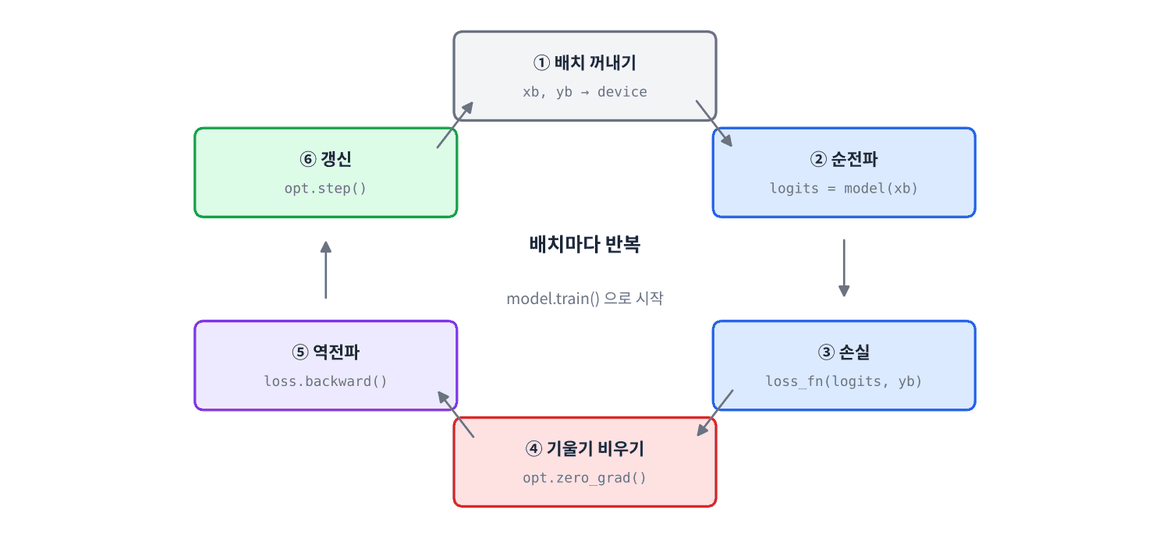

| 단계 | 코드 | NN 과정에서는 |
|---|---|---|
| 배치를 device 로 | `xb, yb = xb.to(device), yb.to(device)` | (없음 — CPU 만) |
| 순전파 | `logits = model(xb)` | `net.predict(x)` |
| 손실 | `loss = loss_fn(logits, yb)` | `SoftmaxWithLoss.forward` |
| 기울기 비우기 | `opt.zero_grad()` | (매번 새 grads 딕셔너리) |
| 역전파 | `loss.backward()` | `net.gradient(x, t)` |
| 갱신 | `opt.step()` | `optimizer.update(params, grads)` |

**문제 5-1** 한 epoch 학습 함수를 완성하세요. 평균 손실을 돌려줍니다.

In [ ]:
def train_one_epoch(model, loader, loss_fn, opt):
    model.____                       # Dropout · BatchNorm 을 학습 모드로
    total, n = 0.0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        loss = loss_fn(logits, yb)
        opt.____
        loss.____
        opt.____
        total += loss.item() * len(xb)
        n += len(xb)
    return total / n

In [ ]:
#@title 🔒 정답 보기 5-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA1LTEg4pSA4pSACmRlZiB0cmFpbl9vbmVfZXBvY2gobW9kZWwsIGxvYWRlciwgbG9zc19m"
    "biwgb3B0KToKICAgIG1vZGVsLnRyYWluKCkgICAgICAgICAgICAgICAgICAgICAgICMgRHJvcG91dCDCtyBCYXRj"
    "aE5vcm0g7J2EIO2VmeyKtSDrqqjrk5zroZwKICAgIHRvdGFsLCBuID0gMC4wLCAwCiAgICBmb3IgeGIsIHliIGlu"
    "IGxvYWRlcjoKICAgICAgICB4YiwgeWIgPSB4Yi50byhkZXZpY2UpLCB5Yi50byhkZXZpY2UpCiAgICAgICAgbG9n"
    "aXRzID0gbW9kZWwoeGIpCiAgICAgICAgbG9zcyA9IGxvc3NfZm4obG9naXRzLCB5YikKICAgICAgICBvcHQuemVy"
    "b19ncmFkKCkKICAgICAgICBsb3NzLmJhY2t3YXJkKCkKICAgICAgICBvcHQuc3RlcCgpCiAgICAgICAgdG90YWwg"
    "Kz0gbG9zcy5pdGVtKCkgKiBsZW4oeGIpCiAgICAgICAgbiArPSBsZW4oeGIpCiAgICByZXR1cm4gdG90YWwgLyBu"
    "Cgrwn5KhIO2VtOyEpApsb3NzLml0ZW0oKSDsnYAgR1BVIOydmCDsiqTsubzrnbzrpbwg7YyM7J207I2sIOyIq+ye"
    "kOuhnCDqsIDsoLjsmLXri4jri6QuIOuwsOy5mCDtgazquLDrpbwg6rOx7ZW0IOuNlO2VnCDrkqQgbiDsnLzroZwg"
    "64KY64iE66m0IOuniOyngOuniSDrsLDsuZjqsIAg7J6R7JWE64+EIOygle2Zle2VnCDtj4nqt6DsnbQg65Cp64uI"
    "64ukLg=="
).decode("utf-8"))

**문제 5-2** 정확도 평가 함수를 완성하세요. 평가는 기울기가 필요 없으니 기록을 끄고, 모델은 평가 모드로.

In [ ]:
def evaluate(model, loader):
    model.____
    correct, n = 0, 0
    with torch.____():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            pred = model(xb).____
            correct += (pred == yb).sum().item()
            n += len(yb)
    return correct / n

In [ ]:
acc0 = evaluate(MLP().to(device), test_loader)
assert 0.0 < acc0 < 0.3; print("✅ 학습 전 정확도:", acc0, "(찍기 ≈ 0.1)")

In [ ]:
#@title 🔒 정답 보기 5-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA1LTIg4pSA4pSACmRlZiBldmFsdWF0ZShtb2RlbCwgbG9hZGVyKToKICAgIG1vZGVsLmV2"
    "YWwoKQogICAgY29ycmVjdCwgbiA9IDAsIDAKICAgIHdpdGggdG9yY2gubm9fZ3JhZCgpOgogICAgICAgIGZvciB4"
    "YiwgeWIgaW4gbG9hZGVyOgogICAgICAgICAgICB4YiwgeWIgPSB4Yi50byhkZXZpY2UpLCB5Yi50byhkZXZpY2Up"
    "CiAgICAgICAgICAgIHByZWQgPSBtb2RlbCh4YikuYXJnbWF4KGRpbT0xKQogICAgICAgICAgICBjb3JyZWN0ICs9"
    "IChwcmVkID09IHliKS5zdW0oKS5pdGVtKCkKICAgICAgICAgICAgbiArPSBsZW4oeWIpCiAgICByZXR1cm4gY29y"
    "cmVjdCAvIG4KCvCfkqEg7ZW07ISkCm1vZGVsLmV2YWwoKSDqs7wgdG9yY2gubm9fZ3JhZCgpIOuKlCDtlZjripQg"
    "7J287J20IOuLpOumheuLiOuLpC4gZXZhbCgpIOydgCBEcm9wb3V0IMK3IEJhdGNoTm9ybSDsnZgg64+Z7J6R7J2E"
    "IOuwlOq+uOqzoCwgbm9fZ3JhZCgpIOuKlCDsl7DsgrAg6riw66Gd7J2EIOuBleuLiOuLpC4g7Y+J6rCAIOuVjOuK"
    "lCDrkZgg64ukLg=="
).decode("utf-8"))

**문제 5-3** MLP 를 Adam(lr 0.001) 으로 **3 epoch** 학습하세요. 모델과 옵티마이저를 만드는 두 줄을 채웁니다. (GPU 로 epoch 당 약 10초, CPU 로 약 15초)

In [ ]:
torch.manual_seed(0)
model = MLP().____
opt = torch.optim.____(model.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()

hist = {"loss": [], "test_acc": []}
for epoch in range(3):
    t0 = time.perf_counter()
    loss = train_one_epoch(model, train_loader, loss_fn, opt)
    acc = evaluate(model, test_loader)
    hist["loss"].append(loss); hist["test_acc"].append(acc)
    print(f"epoch {epoch + 1}  loss {loss:.4f}  test {acc:.4f}  ({time.perf_counter() - t0:.1f} s)")

In [ ]:
assert hist["test_acc"][-1] >= 0.95 and hist["loss"][0] > hist["loss"][-1]; print("✅")

In [ ]:
#@title 🔒 정답 보기 5-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA1LTMg4pSA4pSACnRvcmNoLm1hbnVhbF9zZWVkKDApCm1vZGVsID0gTUxQKCkudG8oZGV2"
    "aWNlKQpvcHQgPSB0b3JjaC5vcHRpbS5BZGFtKG1vZGVsLnBhcmFtZXRlcnMoKSwgbHI9MWUtMykKbG9zc19mbiA9"
    "IG5uLkNyb3NzRW50cm9weUxvc3MoKQoKaGlzdCA9IHsibG9zcyI6IFtdLCAidGVzdF9hY2MiOiBbXX0KZm9yIGVw"
    "b2NoIGluIHJhbmdlKDMpOgogICAgdDAgPSB0aW1lLnBlcmZfY291bnRlcigpCiAgICBsb3NzID0gdHJhaW5fb25l"
    "X2Vwb2NoKG1vZGVsLCB0cmFpbl9sb2FkZXIsIGxvc3NfZm4sIG9wdCkKICAgIGFjYyA9IGV2YWx1YXRlKG1vZGVs"
    "LCB0ZXN0X2xvYWRlcikKICAgIGhpc3RbImxvc3MiXS5hcHBlbmQobG9zcyk7IGhpc3RbInRlc3RfYWNjIl0uYXBw"
    "ZW5kKGFjYykKICAgIHByaW50KGYiZXBvY2gge2Vwb2NoICsgMX0gIGxvc3Mge2xvc3M6LjRmfSAgdGVzdCB7YWNj"
    "Oi40Zn0gICh7dGltZS5wZXJmX2NvdW50ZXIoKSAtIHQwOi4xZn0gcykiKQoK8J+SoSDtlbTshKQK66qo64247J2E"
    "IOuovOyggCAudG8oZGV2aWNlKSDtlZwg65Kk7JeQIOyYte2LsOuniOydtOyggOulvCDrp4zrk5zripQg6rKD7J20"
    "IOyInOyEnOyeheuLiOuLpCAo7Ji17Yuw66eI7J207KCA6rCAIEdQVSDsl5Ag7J6I64qUIO2MjOudvOuvuO2EsOul"
    "vCDquLDslrXtlbTslbwg7ZWoKS4gTk4gRGF5IDMgNzg0LTEwMC0xMCDsnYAgU0dEIDEwIGVwb2NoIOyXkCAwLjk2"
    "OTQg7JiA7Iq164uI64ukLg=="
).decode("utf-8"))

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(range(1, 4), hist["loss"], "o-"); ax[0].set_title("train loss"); ax[0].set_xlabel("epoch")
ax[1].plot(range(1, 4), hist["test_acc"], "o-", color="tab:green"); ax[1].set_title("test accuracy"); ax[1].set_xlabel("epoch")
for a in ax: a.grid(alpha=.3)
plt.show()

**문제 5-4** 학습한 모델을 저장하고, **새 모델**에 불러와 정확도가 같은지 확인하세요. `state_dict()` 는 "파라미터 이름 → 텐서" 딕셔너리입니다.

In [ ]:
torch.save(model.____, "mlp.pt")
print({k: tuple(v.shape) for k, v in model.state_dict().items()})

model2 = MLP().to(device)
model2.____(torch.load("mlp.pt", map_location=device))
acc_loaded = evaluate(model2, test_loader)

In [ ]:
assert acc_loaded == hist["test_acc"][-1]; print("✅ 불러온 모델:", acc_loaded, "| 파일", os.path.getsize("mlp.pt"), "bytes")

In [ ]:
#@title 🔒 정답 보기 5-4 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA1LTQg4pSA4pSACnRvcmNoLnNhdmUobW9kZWwuc3RhdGVfZGljdCgpLCAibWxwLnB0IikK"
    "cHJpbnQoe2s6IHR1cGxlKHYuc2hhcGUpIGZvciBrLCB2IGluIG1vZGVsLnN0YXRlX2RpY3QoKS5pdGVtcygpfSkK"
    "Cm1vZGVsMiA9IE1MUCgpLnRvKGRldmljZSkKbW9kZWwyLmxvYWRfc3RhdGVfZGljdCh0b3JjaC5sb2FkKCJtbHAu"
    "cHQiLCBtYXBfbG9jYXRpb249ZGV2aWNlKSkKYWNjX2xvYWRlZCA9IGV2YWx1YXRlKG1vZGVsMiwgdGVzdF9sb2Fk"
    "ZXIpCgrwn5KhIO2VtOyEpArrqqjrjbgg6rCd7LK0IO2GteynuOqwgCDslYTri4jrnbwg7YyM652866+47YSw66eM"
    "IOyggOyepe2VmOuKlCDqsoPsnbQg7ZGc7KSA7J6F64uI64ukLiDrtojrn6zsmKwg65WM64qUIOqwmeydgCDtgbTr"
    "npjsiqTroZwg67mIIOuqqOuNuOydhCDrp4zrk6Tqs6Ag6rCS7J2EIOyxhOybgeuLiOuLpC4gbWFwX2xvY2F0aW9u"
    "IOydgCBHUFUg7JeQ7IScIOyggOyepe2VnCDtjIzsnbzsnYQgQ1BVIOyXkOyEnCDsl7Qg65WMIO2VhOyalO2VqeuL"
    "iOuLpC4K7YyM7J28IO2BrOq4sCDiiYggNzksNTEwIMOXIDQgYnl0ZXMgKGZsb2F0MzIpIOKJiCAzMTggS0Ig4oCU"
    "IFF1YW50aXphdGlvbiDqs7zrqqnsl5DshJwg7J20IOyIq+yekOulvCDspITsnoXri4jri6Qu"
).decode("utf-8"))

#### ⚠️ 자주 하는 실수

- 평가 뒤 학습을 이어 가는데 `model.train()` 을 다시 안 부름 → Dropout · BN 이 꺼진 채 학습. `train_one_epoch` 첫 줄에 두면 안전합니다.
- `loss` 텐서를 그대로 리스트에 모음 → 그래프가 계속 붙어 메모리가 샙니다. `loss.item()`.
- 옵티마이저를 만든 뒤에 `model.to(device)` → 순서를 지키세요.

#### 📌 5교시 정리

- 학습 루프: `train()` → (to device → forward → loss → zero_grad → backward → step) × 배치.
- 평가: `eval()` + `no_grad()` + `argmax`.
- 저장 · 불러오기: `torch.save(model.state_dict())` / `load_state_dict(torch.load(...))`.

## 6교시 — 디지털 이미지: 픽셀 · 채널 · 정규화

MNIST 는 이미 깨끗하게 다듬어진 28×28 흑백 이미지였습니다. 실제 사진은 **크고, 컬러이고, uint8** 입니다. 사진이 모델 입력 텐서가 되기까지의 변환을 하나씩 직접 해 봅니다.

오늘 쓰는 사진은 8교시 미니 프로젝트용 **종이에 쓴 손글씨 사진 30장** 입니다 (휴대폰으로 찍은 사진처럼 종이 질감 · 조명 · 기울어짐 · 흐림을 합성한 세트, 파일 이름 `d{숫자}_{번호}.jpg`).

> 🎬 **애니메이션** [D1-6 이미지 → 텐서](https://imguru-mooc.github.io/AI_CAMPUS/VB-day1/animation.html#d1-6)
> 📝 **워크시트** [6교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/VB-day1/worksheet.html#t6)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

In [ ]:
zpath = fetch("paper_digits.zip")
with zipfile.ZipFile(zpath) as z:
    z.extractall("data")
paper_files = sorted(f for f in os.listdir("data/paper_digits") if f.endswith(".jpg"))
print(len(paper_files), "장:", paper_files[:5], "...")

img = cv2.imread("data/paper_digits/d3_0.jpg")      # OpenCV 는 BGR 순서로 읽는다
print("shape:", img.shape, "| dtype:", img.dtype, "| 값 범위:", img.min(), "~", img.max())

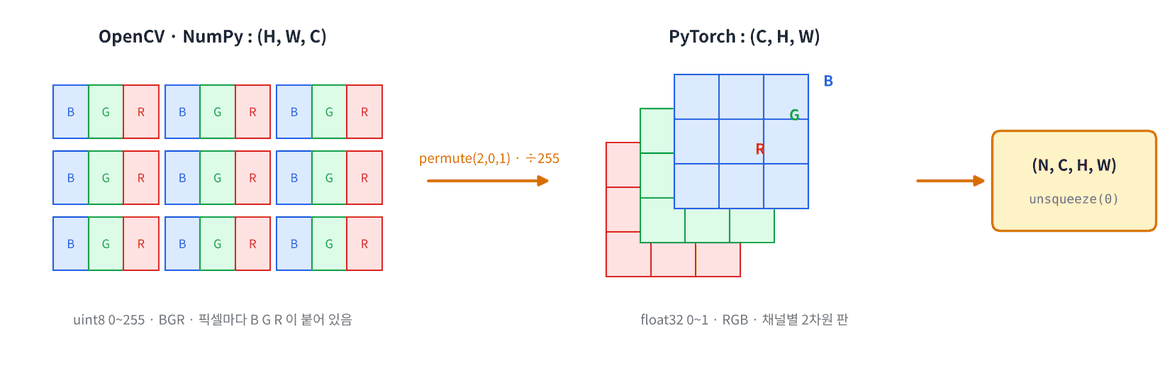

- **OpenCV · NumPy** : (H, W, C) — 한 픽셀의 B, G, R 이 붙어 있다. 값은 **uint8 0~255**, 채널 순서는 **BGR**.
- **PyTorch** : (C, H, W) — 채널별 2차원 판이 3장. 값은 **float32**, 보통 0~1 로 나눈 뒤 평균 · 표준편차로 정규화.
- 모델에는 배치 축을 붙인 **(N, C, H, W)** 로 넣는다.

**문제 6-1** OpenCV 는 이미지를 **BGR** 순서로 읽습니다. matplotlib · PyTorch 사전학습 모델은 **RGB** 를 기대하므로 채널 순서를 뒤집으세요. 슬라이싱 한 번이면 됩니다.

In [ ]:
rgb = img[:, :, ____]

In [ ]:
assert np.array_equal(rgb, cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); print("✅")
fig, ax = plt.subplots(1, 2, figsize=(7, 4))
ax[0].imshow(img); ax[0].set_title("BGR as-is (blue <-> red swapped)"); ax[1].imshow(rgb); ax[1].set_title("RGB")
for a in ax: a.axis("off")
plt.show()

In [ ]:
#@title 🔒 정답 보기 6-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA2LTEg4pSA4pSACnJnYiA9IGltZ1s6LCA6LCA6Oi0xXQoK8J+SoSDtlbTshKQKWzosIDos"
    "IDo6LTFdIOydgCDrp4jsp4Drp4kg7LaV7J2EIOqxsOq+uOuhnCDigJQgQiwgRywgUiDihpIgUiwgRywgQi4g7YyM"
    "656AIOyeie2BrOqwgCBCR1Ig6re464yA66GcIOq3uOumrOuptCDqsIjsg4nsnLzroZwg67O07J2064qUIOqyg+yd"
    "hCDtmZXsnbjtlZjshLjsmpQu"
).decode("utf-8"))

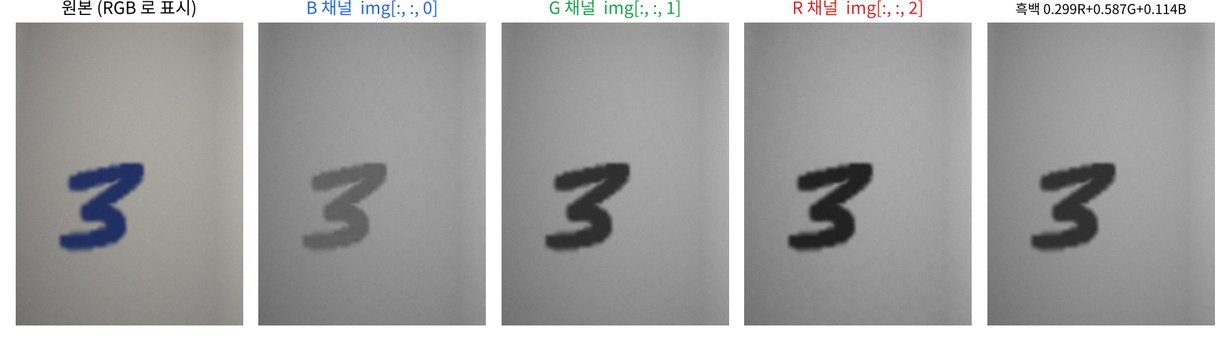

컬러 사진은 밝기 판 3장의 겹침입니다. 파란 잉크는 **B 채널에서 덜 어둡고 R 채널에서 가장 어둡습니다**. 흑백 변환은 세 채널의 **가중 평균** — 사람 눈이 초록에 가장 민감해서 G 의 가중치가 가장 큽니다.

**문제 6-2** 흑백 변환 공식 $\text{Gray} = 0.299R + 0.587G + 0.114B$ 를 직접 계산하고 OpenCV 결과와 비교하세요. `img` 는 BGR 이라는 것을 잊지 마세요.

In [ ]:
B, G, R = img[:, :, 0].astype(np.float32), img[:, :, 1].astype(np.float32), img[:, :, ____].astype(np.float32)
gray_mine = ____
gray_cv = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

In [ ]:
assert np.abs(gray_mine - gray_cv).max() <= 1.0; print("✅ 최대 차이:", np.abs(gray_mine - gray_cv).max())

In [ ]:
#@title 🔒 정답 보기 6-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA2LTIg4pSA4pSACkIsIEcsIFIgPSBpbWdbOiwgOiwgMF0uYXN0eXBlKG5wLmZsb2F0MzIp"
    "LCBpbWdbOiwgOiwgMV0uYXN0eXBlKG5wLmZsb2F0MzIpLCBpbWdbOiwgOiwgMl0uYXN0eXBlKG5wLmZsb2F0MzIp"
    "CmdyYXlfbWluZSA9IDAuMjk5ICogUiArIDAuNTg3ICogRyArIDAuMTE0ICogQgpncmF5X2N2ID0gY3YyLmN2dENv"
    "bG9yKGltZywgY3YyLkNPTE9SX0JHUjJHUkFZKQoK8J+SoSDtlbTshKQKYXN0eXBlKG5wLmZsb2F0MzIpIOulvCDr"
    "qLzsoIAg7ZWY64qUIOydtOycoDogdWludDgg64G866asIOuNlO2VmOuptCAyNTUg66W8IOuEmOuKlCDsiJzqsIQg"
    "MCDrtoDthLAg64uk7IucIOyFieuLiOuLpCAob3ZlcmZsb3cpLiDslYTrnpgg7IWA7JeQ7IScIO2ZleyduO2VmOyE"
    "uOyalC4="
).decode("utf-8"))

In [ ]:
# uint8 overflow — 이미지 계산의 가장 흔한 함정
p = np.array([[200, 250]], dtype=np.uint8)          # 픽셀 2개짜리 1×2 이미지
print("uint8 + 100 :", p + np.uint8(100), " ← 300 이 44 로, 350 이 94 로")
print("float + 100 :", p.astype(np.float32) + 100)
print("cv2.add      :", cv2.add(p, np.full_like(p, 100)), " ← OpenCV 는 255 에서 멈춤 (saturation)")

**문제 6-3** `transforms.ToTensor()` 가 하는 일을 직접 하세요: **HWC → CHW, uint8 → float32, ÷255**. (`.copy()` 는 [::-1] 로 뒤집힌 배열의 메모리를 다시 연속으로 만들어 줍니다.)

In [ ]:
t_mine = torch.from_numpy(rgb.copy()).____.float() / ____
t_tv = transforms.ToTensor()(rgb.copy())
print(tuple(t_mine.shape), t_mine.dtype)

In [ ]:
assert t_mine.shape == (3, 640, 480) and torch.allclose(t_mine, t_tv); print("✅")

In [ ]:
#@title 🔒 정답 보기 6-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA2LTMg4pSA4pSACnRfbWluZSA9IHRvcmNoLmZyb21fbnVtcHkocmdiLmNvcHkoKSkucGVy"
    "bXV0ZSgyLCAwLCAxKS5mbG9hdCgpIC8gMjU1CnRfdHYgPSB0cmFuc2Zvcm1zLlRvVGVuc29yKCkocmdiLmNvcHko"
    "KSkKcHJpbnQodHVwbGUodF9taW5lLnNoYXBlKSwgdF9taW5lLmR0eXBlKQoK8J+SoSDtlbTshKQKcGVybXV0ZSgy"
    "LCAwLCAxKTog7IOIIDDrsogg7LaVID0g7JibIDLrsogoQyksIOyDiCAx67KIID0g7JibIDDrsogoSCksIOyDiCAy"
    "67KIID0g7JibIDHrsogoVyku"
).decode("utf-8"))

**문제 6-4** 사전학습 모델(Day 3) 은 보통 **224×224** 입력을 받습니다. 가운데를 정사각형으로 자른 뒤 224×224 로 줄이고, 배치 축을 붙여 (1, 3, 224, 224) 를 만드세요.

In [ ]:
h, w = rgb.shape[:2]
s = min(h, w)
top, left = (h - s) // 2, (w - s) // 2
crop = rgb[top:top + s, ____]
small_img = cv2.resize(crop, (____), interpolation=cv2.INTER_AREA)
batch = torch.from_numpy(small_img).permute(2, 0, 1).float().div(255).____

In [ ]:
assert crop.shape == (480, 480, 3) and small_img.shape == (224, 224, 3) and batch.shape == (1, 3, 224, 224); print("✅")
plt.imshow(small_img); plt.axis("off"); plt.title("center crop 480 -> resize 224"); plt.show()

In [ ]:
#@title 🔒 정답 보기 6-4 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA2LTQg4pSA4pSACmgsIHcgPSByZ2Iuc2hhcGVbOjJdCnMgPSBtaW4oaCwgdykKdG9wLCBs"
    "ZWZ0ID0gKGggLSBzKSAvLyAyLCAodyAtIHMpIC8vIDIKY3JvcCA9IHJnYlt0b3A6dG9wICsgcywgbGVmdDpsZWZ0"
    "ICsgc10Kc21hbGxfaW1nID0gY3YyLnJlc2l6ZShjcm9wLCAoMjI0LCAyMjQpLCBpbnRlcnBvbGF0aW9uPWN2Mi5J"
    "TlRFUl9BUkVBKQpiYXRjaCA9IHRvcmNoLmZyb21fbnVtcHkoc21hbGxfaW1nKS5wZXJtdXRlKDIsIDAsIDEpLmZs"
    "b2F0KCkuZGl2KDI1NSkudW5zcXVlZXplKDApCgrwn5KhIO2VtOyEpApjdjIucmVzaXplIOydmCDtgazquLAg7J24"
    "7J6Q64qUICjqsIDroZwgVywg7IS466GcIEgpIOyInOyEnOyeheuLiOuLpCDigJQgc2hhcGUg7J2YIChILCBXKSDs"
    "mYAg67CY64yA6528IOygleyCrOqwge2YleydtCDslYTri5Ag65WMIOyekOyjvCDti4Drpr3ri4jri6QuIOykhOyd"
    "vCDrlYzripQgSU5URVJfQVJFQSDqsIAg6rOE64uoIO2YhOyDgeydtCDsoIHsirXri4jri6Qu"
).decode("utf-8"))

**문제 6-5** 정규화 — 사전학습 모델은 ImageNet 의 채널별 평균 · 표준편차로 정규화된 입력을 기대합니다. (C, H, W) 텐서와 길이 3 벡터를 브로드캐스팅하려면 벡터를 **(3, 1, 1)** 로 바꿔야 합니다.

In [ ]:
mean = torch.tensor([0.485, 0.456, 0.406])
std = torch.tensor([0.229, 0.224, 0.225])
x = batch[0]                                              # (3, 224, 224)
x_norm = (x - mean.view(____)) / std.view(____)

In [ ]:
ref = transforms.Normalize(mean.tolist(), std.tolist())(x)
assert torch.allclose(x_norm, ref, atol=1e-6); print("✅ 채널별 평균:", x_norm.mean(dim=(1, 2)))

In [ ]:
#@title 🔒 정답 보기 6-5 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA2LTUg4pSA4pSACm1lYW4gPSB0b3JjaC50ZW5zb3IoWzAuNDg1LCAwLjQ1NiwgMC40MDZd"
    "KQpzdGQgPSB0b3JjaC50ZW5zb3IoWzAuMjI5LCAwLjIyNCwgMC4yMjVdKQp4ID0gYmF0Y2hbMF0gICAgICAgICAg"
    "ICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgIyAoMywgMjI0LCAyMjQpCnhfbm9ybSA9ICh4IC0g"
    "bWVhbi52aWV3KDMsIDEsIDEpKSAvIHN0ZC52aWV3KDMsIDEsIDEpCgrwn5KhIO2VtOyEpApOTiDqs7zsoJUgRGF5"
    "IDEg7ZGc7KSA7ZmUICh4IOKIkiDOvCkvz4Mg66W8IOyxhOuEkOuniOuLpCDtlZwg6rKD7J6F64uI64ukLiB2aWV3"
    "KDMpIOq3uOuMgOuhnOuptCDrp4jsp4Drp4kg7LaVKFcpIOqzvCDrp57stpTroKTri6Qg7Jik66WY6rCAIOuCqeuL"
    "iOuLpC4K7ZWZ7Iq17ZWgIOuVjCDsk7Qg7KCV6rec7ZmU66W8IOy2lOuhoCDrlYzrj4QgKirrmJHqsJnsnbQqKiDt"
    "lbTslbwg7ZWp64uI64ukIOKAlCA46rWQ7Iuc7JeQ7IScIOyngeygkSDqsqrsirXri4jri6Qu"
).decode("utf-8"))

#### ⚠️ 자주 하는 실수

- BGR 을 RGB 로 안 바꾸고 사전학습 모델에 넣음 → 오류는 안 나고 정확도만 조용히 떨어집니다.
- `cv2.resize(img, (H, W))` → 크기 인자는 **(W, H)**.
- uint8 상태로 더하기 · 빼기 → overflow. float 로 바꾸고 계산.

#### 📌 6교시 정리

- OpenCV: (H, W, C) uint8 BGR → PyTorch: (N, C, H, W) float32 RGB, 0~1, 정규화.
- 흑백 = 0.299R + 0.587G + 0.114B.
- crop → resize → ToTensor → Normalize → unsqueeze(0). 학습과 추론의 전처리는 같아야 한다.

## 7교시 — 영상 파일 파이프라인

영상은 **같은 크기 이미지(프레임)의 연속**입니다. 카메라든 영상 파일이든 코드에서는 `cv2.VideoCapture` 로 열어 **한 프레임씩 꺼내는 루프**가 됩니다. 이번 과정은 카메라 대신 영상 파일로 실습하지만, 열 때 주소만 바꾸면 같은 코드가 카메라에서도 돕니다.

오늘은 먼저 MNIST 숫자가 오른쪽에서 왼쪽으로 지나가는 **테스트 영상을 직접 만들고**, 그 영상을 읽어 처리한 뒤 결과 영상을 저장합니다.

> 🎬 **애니메이션** [D1-7 영상 = 프레임의 연속](https://imguru-mooc.github.io/AI_CAMPUS/VB-day1/animation.html#d1-7)
> 📝 **워크시트** [7교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/VB-day1/worksheet.html#t7)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

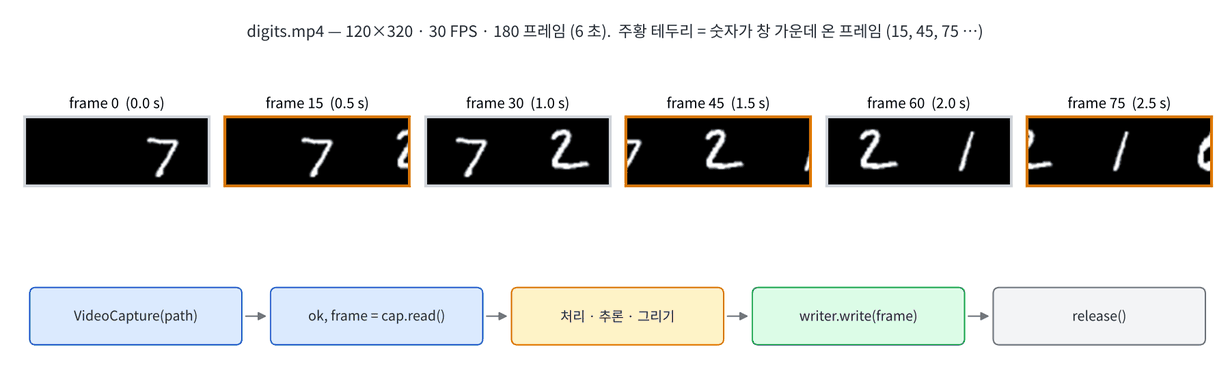

| 용어 | 뜻 | 오늘 영상 |
|---|---|---|
| 프레임 (frame) | 영상 속 이미지 한 장, (H, W, 3) uint8 BGR | 120 × 320 |
| FPS | 1초에 보여 주는 프레임 수 | 30 |
| 프레임 수 | 영상 길이(초) × FPS | 6초 × 30 = 180 |
| 코덱 · fourcc | 프레임을 압축하는 방식의 4글자 이름 | `mp4v` |

In [ ]:
# 테스트 영상 재료 — test 셋의 숫자 6개를 96×96 으로 키워 가로로 이어 붙인 '띠'
VID_DIGITS = [7, 2, 1, 0, 4, 1]                     # test_set 0~5번 이미지의 정답
digits_img = test_set.data[:6].numpy()              # (6, 28, 28) uint8
CELL, H_V, W_V, FPS = 160, 120, 320, 30
strip = np.zeros((H_V, CELL * (len(digits_img) + 2)), np.uint8)
for k, d in enumerate(digits_img):
    big = cv2.resize(d, (96, 96), interpolation=cv2.INTER_CUBIC)
    x0 = CELL * (k + 1) + (CELL - 96) // 2
    strip[12:108, x0:x0 + 96] = big
print("띠 shape:", strip.shape)

def frame_at(i):
    """i 번째 프레임: 띠를 1초에 CELL 픽셀씩 왼쪽으로 민 창 (W_V 폭)"""
    off = int(i * CELL / FPS)          # i = 15, 45, 75 … 에서 k 번째 숫자가 창 가운데
    win = strip[:, off:off + W_V]
    return cv2.cvtColor(win, cv2.COLOR_GRAY2BGR)

plt.figure(figsize=(10, 1.5)); plt.imshow(strip, cmap="gray"); plt.axis("off"); plt.show()

**문제 7-1** 프레임 180장(6초)을 `digits.mp4` 로 저장하세요.

- `cv2.VideoWriter(파일, fourcc, FPS, (가로, 세로))` — 크기가 **(W, H)** 순서인 것에 주의. 틀리면 오류 없이 **빈 파일**이 만들어집니다.
- 다 쓰면 `release()` 로 닫아야 파일이 완성됩니다.

In [ ]:
fourcc = cv2.VideoWriter_fourcc(*"mp4v")
writer = cv2.VideoWriter("digits.mp4", fourcc, ____, (____))
for i in range(6 * FPS):
    writer.____(frame_at(i))
writer.____
print("파일 크기:", os.path.getsize("digits.mp4"), "bytes")

In [ ]:
assert os.path.getsize("digits.mp4") > 10_000; print("✅")

In [ ]:
#@title 🔒 정답 보기 7-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA3LTEg4pSA4pSACmZvdXJjYyA9IGN2Mi5WaWRlb1dyaXRlcl9mb3VyY2MoKiJtcDR2IikK"
    "d3JpdGVyID0gY3YyLlZpZGVvV3JpdGVyKCJkaWdpdHMubXA0IiwgZm91cmNjLCBGUFMsIChXX1YsIEhfVikpCmZv"
    "ciBpIGluIHJhbmdlKDYgKiBGUFMpOgogICAgd3JpdGVyLndyaXRlKGZyYW1lX2F0KGkpKQp3cml0ZXIucmVsZWFz"
    "ZSgpCnByaW50KCLtjIzsnbwg7YGs6riwOiIsIG9zLnBhdGguZ2V0c2l6ZSgiZGlnaXRzLm1wNCIpLCAiYnl0ZXMi"
    "KQoK8J+SoSDtlbTshKQKVmlkZW9Xcml0ZXIg64qUIO2BrOq4sOqwgCDrp57sp4Ag7JWK64qUIO2UhOugiOyehOyd"
    "hCDsobDsmqntnogg67KE66a964uI64ukLiDtjIzsnbzsnbQg7IiY67CxIGJ5dGVzIOuwluyXkCDslYgg65CY66m0"
    "IChXLCBIKSDsiJzshJzrgpgg7ZSE66CI7J6EIO2BrOq4sOulvCDsnZjsi6ztlZjshLjsmpQu"
).decode("utf-8"))

**문제 7-2** 저장한 영상을 열어 **속성**을 읽으세요. `cap.get(cv2.CAP_PROP_...)` 은 float 을 돌려주므로 int 로 바꿉니다.

In [ ]:
cap = cv2.VideoCapture("digits.mp4")
n_frames = int(cap.get(cv2.____))
fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.____))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
cap.release()
print(f"{n_frames} 프레임 · {fps:.0f} FPS · {width}×{height} · {n_frames / fps:.1f} 초")

In [ ]:
assert (n_frames, round(fps), width, height) == (180, 30, 320, 120); print("✅")

In [ ]:
#@title 🔒 정답 보기 7-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA3LTIg4pSA4pSACmNhcCA9IGN2Mi5WaWRlb0NhcHR1cmUoImRpZ2l0cy5tcDQiKQpuX2Zy"
    "YW1lcyA9IGludChjYXAuZ2V0KGN2Mi5DQVBfUFJPUF9GUkFNRV9DT1VOVCkpCmZwcyA9IGNhcC5nZXQoY3YyLkNB"
    "UF9QUk9QX0ZQUykKd2lkdGggPSBpbnQoY2FwLmdldChjdjIuQ0FQX1BST1BfRlJBTUVfV0lEVEgpKQpoZWlnaHQg"
    "PSBpbnQoY2FwLmdldChjdjIuQ0FQX1BST1BfRlJBTUVfSEVJR0hUKSkKY2FwLnJlbGVhc2UoKQpwcmludChmIntu"
    "X2ZyYW1lc30g7ZSE66CI7J6EIMK3IHtmcHM6LjBmfSBGUFMgwrcge3dpZHRofcOXe2hlaWdodH0gwrcge25fZnJh"
    "bWVzIC8gZnBzOi4xZn0g7LSIIik="
).decode("utf-8"))

**문제 7-3** 프레임 하나를 모델 입력으로 바꾸는 함수를 만드세요. 이번 영상은 MNIST 처럼 검은 배경에 흰 숫자이므로, **가운데 정사각형 120×120 을 잘라** 흑백 → 28×28 → 0~1 → (1, 1, 28, 28) 로 만들면 됩니다.

In [ ]:
def frame_to_input(frame):
    gray = cv2.cvtColor(frame, cv2.____)          # (120, 320)
    h, w = gray.shape
    c = gray[:, (w - h) // 2:(w - h) // 2 + ____]             # 가운데 (120, 120)
    small = cv2.resize(c, (28, 28), interpolation=cv2.INTER_AREA)
    return torch.from_numpy(small).float().div(255)____   # (1, 1, 28, 28)

In [ ]:
cap = cv2.VideoCapture("digits.mp4")
for _ in range(45): ok, fr = cap.read()                      # 1.5초 지점 프레임
cap.release()
inp = frame_to_input(fr)
assert inp.shape == (1, 1, 28, 28) and inp.dtype == torch.float32 and inp.max() <= 1; print("✅")
plt.figure(figsize=(6, 2))
plt.subplot(1, 2, 1); plt.imshow(fr[:, :, ::-1]); plt.title("frame 45"); plt.axis("off")
plt.subplot(1, 2, 2); plt.imshow(inp[0, 0], cmap="gray"); plt.title("model input 28×28"); plt.axis("off"); plt.show()

In [ ]:
#@title 🔒 정답 보기 7-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA3LTMg4pSA4pSACmRlZiBmcmFtZV90b19pbnB1dChmcmFtZSk6CiAgICBncmF5ID0gY3Yy"
    "LmN2dENvbG9yKGZyYW1lLCBjdjIuQ09MT1JfQkdSMkdSQVkpICAgICAgICAgICMgKDEyMCwgMzIwKQogICAgaCwg"
    "dyA9IGdyYXkuc2hhcGUKICAgIGMgPSBncmF5WzosICh3IC0gaCkgLy8gMjoodyAtIGgpIC8vIDIgKyBoXSAgICAg"
    "ICAgICAgICAjIOqwgOyatOuNsCAoMTIwLCAxMjApCiAgICBzbWFsbCA9IGN2Mi5yZXNpemUoYywgKDI4LCAyOCks"
    "IGludGVycG9sYXRpb249Y3YyLklOVEVSX0FSRUEpCiAgICByZXR1cm4gdG9yY2guZnJvbV9udW1weShzbWFsbCku"
    "ZmxvYXQoKS5kaXYoMjU1KVtOb25lLCBOb25lXSAgICMgKDEsIDEsIDI4LCAyOCkKCvCfkqEg7ZW07ISkCltOb25l"
    "LCBOb25lXSDsnYAgdW5zcXVlZXplKDApLnVuc3F1ZWV6ZSgwKSDqs7wg6rCZ7Iq164uI64ukIOKAlCDrp6gg7JWe"
    "7JeQIOuwsOy5mCDstpXqs7wg7LGE64SQIOy2leydhCDrhKPsirXri4jri6Qu"
).decode("utf-8"))

**문제 7-4** 읽기 → 처리 → 쓰기 루프를 완성하세요. 처리 내용: 가운데 120×120 영역에 상자를 그리고, 프레임 번호와 처리 시간을 글자로 넣습니다. `cap.read()` 는 (성공 여부, 프레임) 을 돌려주고, 영상이 끝나면 성공 여부가 False 입니다.

In [ ]:
cap = cv2.VideoCapture("digits.mp4")
writer = cv2.VideoWriter("digits_boxed.mp4", cv2.VideoWriter_fourcc(*"mp4v"), FPS, (W_V, H_V))
count, times = 0, []
while True:
    ok, frame = cap.____
    if ____:
        break
    t0 = time.perf_counter()
    cv2.rectangle(frame, (100, 0), (219, 119), (0, 200, 255), 2)
    cv2.putText(frame, f"#{count}", (6, 18), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)
    writer.write(frame)
    times.append((time.perf_counter() - t0) * 1000)
    count += 1
cap.release(); writer.release()
print(f"{count} 프레임 처리 · 프레임당 평균 {np.mean(times):.3f} ms")

In [ ]:
assert count == 180 and os.path.getsize("digits_boxed.mp4") > 10_000; print("✅")

In [ ]:
#@title 🔒 정답 보기 7-4 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA3LTQg4pSA4pSACmNhcCA9IGN2Mi5WaWRlb0NhcHR1cmUoImRpZ2l0cy5tcDQiKQp3cml0"
    "ZXIgPSBjdjIuVmlkZW9Xcml0ZXIoImRpZ2l0c19ib3hlZC5tcDQiLCBjdjIuVmlkZW9Xcml0ZXJfZm91cmNjKCoi"
    "bXA0diIpLCBGUFMsIChXX1YsIEhfVikpCmNvdW50LCB0aW1lcyA9IDAsIFtdCndoaWxlIFRydWU6CiAgICBvaywg"
    "ZnJhbWUgPSBjYXAucmVhZCgpCiAgICBpZiBub3Qgb2s6CiAgICAgICAgYnJlYWsKICAgIHQwID0gdGltZS5wZXJm"
    "X2NvdW50ZXIoKQogICAgY3YyLnJlY3RhbmdsZShmcmFtZSwgKDEwMCwgMCksICgyMTksIDExOSksICgwLCAyMDAs"
    "IDI1NSksIDIpCiAgICBjdjIucHV0VGV4dChmcmFtZSwgZiIje2NvdW50fSIsICg2LCAxOCksIGN2Mi5GT05UX0hF"
    "UlNIRVlfU0lNUExFWCwgMC41LCAoMCwgMjU1LCAwKSwgMSkKICAgIHdyaXRlci53cml0ZShmcmFtZSkKICAgIHRp"
    "bWVzLmFwcGVuZCgodGltZS5wZXJmX2NvdW50ZXIoKSAtIHQwKSAqIDEwMDApCiAgICBjb3VudCArPSAxCmNhcC5y"
    "ZWxlYXNlKCk7IHdyaXRlci5yZWxlYXNlKCkKcHJpbnQoZiJ7Y291bnR9IO2UhOugiOyehCDsspjrpqwgwrcg7ZSE"
    "66CI7J6E64u5IO2Pieq3oCB7bnAubWVhbih0aW1lcyk6LjNmfSBtcyIpCgrwn5KhIO2VtOyEpAp3aGlsZSBUcnVl"
    "ICsgcmVhZCgpICsgYnJlYWsg6rCAIOy5tOuplOudvCDCtyDsmIHsg4Eg7YyM7J28IMK3IOyKpO2KuOumvCDrqqjr"
    "kZDsnZgg6riw67O47ZiV7J6F64uI64ukLiDsubTrqZTrnbzrnbzrqbQg7JiB7IOB7J20ICfrgZ3rgpjripQnIOyd"
    "vOydtCDsl4bsnLzrr4DroZwg7YKkIOyeheugpeydtOuCmCDsi5zqsITsnLzroZwg66mI7Lal64uI64ukLg=="
).decode("utf-8"))

### 결과 영상 보기

`mp4v` 코덱은 브라우저에서 재생되지 않는 경우가 많습니다. Colab 에는 `ffmpeg` 가 있으므로 **H.264** 로 바꿔서 노트북 안에 재생합니다. ffmpeg 가 없는 환경에서는 프레임 몇 장을 그림으로 봅니다.

In [ ]:
import shutil, base64
from IPython.display import HTML, display

def show_video(path, width=480):
    if shutil.which("ffmpeg"):
        h264 = path.replace(".mp4", "_h264.mp4")
        os.system(f"ffmpeg -y -loglevel error -i {path} -vcodec libx264 -pix_fmt yuv420p {h264}")
        b64 = base64.b64encode(open(h264, "rb").read()).decode()
        display(HTML(f'<video width="{width}" controls loop autoplay muted src="data:video/mp4;base64,{b64}"></video>'))
    else:
        cap = cv2.VideoCapture(path); frames = []
        for i in range(int(cap.get(cv2.CAP_PROP_FRAME_COUNT))):
            ok, f = cap.read()
            if i % 30 == 15: frames.append(f[:, :, ::-1])
        cap.release()
        plt.figure(figsize=(12, 2))
        for k, f in enumerate(frames):
            plt.subplot(1, len(frames), k + 1); plt.imshow(f); plt.axis("off")
        plt.show()

show_video("digits_boxed.mp4")

#### ⚠️ 자주 하는 실수

- `VideoWriter(..., (H, W))` → 오류 없이 빈 영상. 크기는 **(W, H)**.
- `release()` 를 안 함 → 파일이 덜 써져서 재생이 안 됩니다.
- `cap.read()` 의 `ok` 를 확인하지 않음 → 영상 끝에서 `frame` 이 `None` 이라 다음 줄에서 오류.

#### 📌 7교시 정리

- 영상 = 프레임 (H, W, 3) uint8 BGR 의 연속, 길이 = 프레임 수 / FPS.
- `VideoCapture` → `while: ok, frame = read()` → 처리 → `VideoWriter.write` → `release()`.
- 영상 파일 대신 카메라를 열어도 루프는 같다 (프로젝트 과목에서).

## 8교시 — 미니 프로젝트: 종이 손글씨 · 영상 숫자 인식

오늘 배운 것을 모두 엮습니다. NN Day 5 의 SimpleConvNet 을 PyTorch 로 학습하고, **MNIST 가 아닌 데이터** — 종이에 쓴 손글씨 사진 30장과 7교시 영상 — 를 인식합니다.

| 과제 | 내용 | 배점 |
|---|---|---|
| 1 | SimpleConvNet 을 `nn.Module` 로 구현 (433,890 파라미터) | 20 |
| 2 | 2 epoch 학습 — test 정확도 ≥ 0.98 | 25 |
| 3 | 사진 전처리 함수 `preprocess` 구현 | 25 |
| 4 | 사진 30장 정확도 — 그냥 줄이기 vs 전처리 | 10 |
| 5 | 영상 프레임 인식 · 결과 영상 저장 | 10 |
| 6 | 결과 해석 (마크다운 답변) | 10 |

과제 끝의 **채점 셀**을 실행하면 자동 채점 점수가 나옵니다(과제 6 은 강사 채점). 제출은 채점 셀 결과가 보이는 상태로 이 노트북을 공유합니다.

> 🎬 **애니메이션** [D1-8 종이 손글씨 전처리](https://imguru-mooc.github.io/AI_CAMPUS/VB-day1/animation.html#d1-8)
> 📝 **워크시트** [8교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/VB-day1/worksheet.html#t8)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

### 과제 1 — SimpleConvNet (20점)

1교시의 `nn.Sequential` 과 같은 구조를 `nn.Module` 클래스로 쓰세요. 계층 이름은 `conv`, `fc1`, `fc2`.

In [ ]:
class SimpleConvNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(1, 30, 5)
        self.pool = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(____, 100)
        self.fc2 = nn.Linear(100, 10)

    def forward(self, x):
        x = self.pool(F.relu(____))      # (N, 30, 12, 12)
        x = x.flatten(1)
        x = F.relu(self.fc1(x))
        return ____

In [ ]:
#@title 🔒 정답 보기 8-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTEg4pSA4pSACmNsYXNzIFNpbXBsZUNvbnZOZXQobm4uTW9kdWxlKToKICAgIGRlZiBf"
    "X2luaXRfXyhzZWxmKToKICAgICAgICBzdXBlcigpLl9faW5pdF9fKCkKICAgICAgICBzZWxmLmNvbnYgPSBubi5D"
    "b252MmQoMSwgMzAsIDUpCiAgICAgICAgc2VsZi5wb29sID0gbm4uTWF4UG9vbDJkKDIpCiAgICAgICAgc2VsZi5m"
    "YzEgPSBubi5MaW5lYXIoMzAgKiAxMiAqIDEyLCAxMDApCiAgICAgICAgc2VsZi5mYzIgPSBubi5MaW5lYXIoMTAw"
    "LCAxMCkKCiAgICBkZWYgZm9yd2FyZChzZWxmLCB4KToKICAgICAgICB4ID0gc2VsZi5wb29sKEYucmVsdShzZWxm"
    "LmNvbnYoeCkpKSAgICAgICMgKE4sIDMwLCAxMiwgMTIpCiAgICAgICAgeCA9IHguZmxhdHRlbigxKQogICAgICAg"
    "IHggPSBGLnJlbHUoc2VsZi5mYzEoeCkpCiAgICAgICAgcmV0dXJuIHNlbGYuZmMyKHgp"
).decode("utf-8"))

### 과제 2 — 학습 (25점)

5교시의 `train_one_epoch` · `evaluate` 를 그대로 씁니다. Adam(lr 0.001), 배치 100, **2 epoch**. (GPU 로 epoch 당 약 10초, CPU 로 약 1분)

In [ ]:
torch.manual_seed(0)
cnn = SimpleConvNet().____
opt = torch.optim.Adam(cnn.parameters(), lr=1e-3)
cnn_hist = []
for epoch in range(2):
    t0 = time.perf_counter()
    loss = ____
    acc = ____
    cnn_hist.append(acc)
    print(f"epoch {epoch + 1}  loss {loss:.4f}  test {acc:.4f}  ({time.perf_counter() - t0:.1f} s)")
torch.save(cnn.state_dict(), "cnn.pt")

In [ ]:
#@title 🔒 정답 보기 8-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTIg4pSA4pSACnRvcmNoLm1hbnVhbF9zZWVkKDApCmNubiA9IFNpbXBsZUNvbnZOZXQo"
    "KS50byhkZXZpY2UpCm9wdCA9IHRvcmNoLm9wdGltLkFkYW0oY25uLnBhcmFtZXRlcnMoKSwgbHI9MWUtMykKY25u"
    "X2hpc3QgPSBbXQpmb3IgZXBvY2ggaW4gcmFuZ2UoMik6CiAgICB0MCA9IHRpbWUucGVyZl9jb3VudGVyKCkKICAg"
    "IGxvc3MgPSB0cmFpbl9vbmVfZXBvY2goY25uLCB0cmFpbl9sb2FkZXIsIG5uLkNyb3NzRW50cm9weUxvc3MoKSwg"
    "b3B0KQogICAgYWNjID0gZXZhbHVhdGUoY25uLCB0ZXN0X2xvYWRlcikKICAgIGNubl9oaXN0LmFwcGVuZChhY2Mp"
    "CiAgICBwcmludChmImVwb2NoIHtlcG9jaCArIDF9ICBsb3NzIHtsb3NzOi40Zn0gIHRlc3Qge2FjYzouNGZ9ICAo"
    "e3RpbWUucGVyZl9jb3VudGVyKCkgLSB0MDouMWZ9IHMpIikKdG9yY2guc2F2ZShjbm4uc3RhdGVfZGljdCgpLCAi"
    "Y25uLnB0Iik="
).decode("utf-8"))

### 사진을 그냥 넣으면?

MNIST 로 99% 가까이 맞히는 모델에 종이 사진을 **흑백 → 28×28 → ÷255** 만 해서 넣어 봅니다.

In [ ]:
def predict(model, x):
    model.eval()
    with torch.no_grad():
        p = torch.softmax(model(x.to(device)), dim=1)[0].cpu()
    return int(p.argmax()), float(p.max())

def naive(img_bgr):
    g = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    return torch.from_numpy(cv2.resize(g, (28, 28), interpolation=cv2.INTER_AREA)).float().div(255)[None, None]

fig, ax = plt.subplots(2, 6, figsize=(12, 4.5))
for k, fn in enumerate(paper_files[::5][:6]):
    im = cv2.imread(f"data/paper_digits/{fn}")
    pred, conf = predict(cnn, naive(im))
    ax[0, k].imshow(im[:, :, ::-1]); ax[0, k].set_title(f"label {fn[1]}"); ax[0, k].axis("off")
    ax[1, k].imshow(naive(im)[0, 0], cmap="gray"); ax[1, k].set_title(f"pred {pred} ({conf:.2f})", color="green" if str(pred) == fn[1] else "red"); ax[1, k].axis("off")
plt.tight_layout(); plt.show()

MNIST 는 **검은 배경에 흰 글씨**, 숫자가 **20×20 상자 안에, 무게중심이 가운데** 오도록 다듬어진 데이터입니다. 사진은 흰 종이에 어두운 글씨, 숫자가 작고 한쪽에 치우쳐 있으며, 조명 · 그림자 · 줄이 있습니다. 모델이 배운 세상과 입력이 다르면 아무리 좋은 모델도 틀립니다 — **학습 데이터와 같은 모양으로 입력을 맞추는 것이 전처리**입니다.

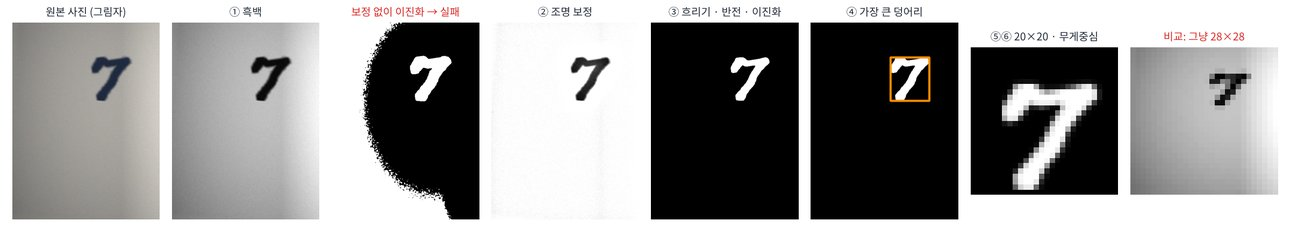

| 단계 | 코드 | 이유 |
|---|---|---|
| ① 흑백 | `cvtColor(BGR2GRAY)` | 모델 입력은 1채널 |
| ② 조명 보정 | `divide(g, GaussianBlur(g, (0, 0), 25), scale=255)` | 아주 크게 흐린 이미지 = 조명 · 그림자만 남은 배경. 원본을 배경으로 나누면 밝기가 평평해진다 |
| ③ 흐리기 · 반전 + 이진화 | `threshold(..., THRESH_BINARY_INV + THRESH_OTSU)` | 흰 배경 → 검은 배경, 글씨만 255. 기준값은 Otsu 가 자동으로 |
| ④ 숫자만 자르기 | 가장 큰 덩어리(contour) 의 bounding box | 줄 · 얼룩 · 여백 제거 |
| ⑤ 20×20 에 맞추기 | 긴 변을 20 으로, 비율 유지 | MNIST 규칙 |
| ⑥ 28×28 가운데 놓기 | 무게중심을 (14, 14) 로 | MNIST 규칙 |

### 과제 3 — `preprocess` (25점)

위 표의 단계를 완성하세요. 반환값은 (1, 1, 28, 28) float32 0~1 텐서.

In [ ]:
def preprocess(img_bgr):
    g = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    bg = cv2.GaussianBlur(g, (0, 0), 25)             # ② 조명 · 그림자만 남은 배경
    g = cv2.divide(g, ____, scale=255)                #    배경으로 나눠 밝기를 평평하게
    g = cv2.GaussianBlur(g, (5, 5), 0)                # ③
    _, bw = cv2.threshold(g, 0, 255, cv2.____ + cv2.THRESH_OTSU)
    bw = cv2.morphologyEx(bw, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))   # 가는 줄 · 점 지우기

    # ④ 가장 큰 덩어리의 bounding box
    contours, _ = cv2.findContours(bw, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    c = max(contours, key=____)
    x, y, w, h = cv2.boundingRect(c)
    digit = bw[y:y + h, x:x + w]

    # ⑤ 긴 변을 20 으로, 비율 유지
    scale = 20.0 / ____
    nw, nh = max(1, round(w * scale)), max(1, round(h * scale))
    digit = cv2.resize(digit, (nw, nh), interpolation=cv2.INTER_AREA)

    # ⑥ 28×28 캔버스 가운데에 놓고, 무게중심을 (14, 14) 로 이동
    canvas = np.zeros((28, 28), np.uint8)
    top, left = (28 - nh) // 2, (28 - nw) // 2
    canvas[top:top + nh, left:left + nw] = digit
    m = cv2.moments(canvas)
    cx, cy = m["m10"] / m["m00"], m["m01"] / m["m00"]
    M = np.float32([[1, 0, ____], [0, 1, ____]])
    canvas = cv2.warpAffine(canvas, M, (28, 28))
    return torch.from_numpy(canvas).float().div(255)[None, None]

In [ ]:
#@title 🔒 정답 보기 8-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTMg4pSA4pSACmRlZiBwcmVwcm9jZXNzKGltZ19iZ3IpOgogICAgZyA9IGN2Mi5jdnRD"
    "b2xvcihpbWdfYmdyLCBjdjIuQ09MT1JfQkdSMkdSQVkpCiAgICBiZyA9IGN2Mi5HYXVzc2lhbkJsdXIoZywgKDAs"
    "IDApLCAyNSkKICAgIGcgPSBjdjIuZGl2aWRlKGcsIGJnLCBzY2FsZT0yNTUpCiAgICBnID0gY3YyLkdhdXNzaWFu"
    "Qmx1cihnLCAoNSwgNSksIDApCiAgICBfLCBidyA9IGN2Mi50aHJlc2hvbGQoZywgMCwgMjU1LCBjdjIuVEhSRVNI"
    "X0JJTkFSWV9JTlYgKyBjdjIuVEhSRVNIX09UU1UpCiAgICBidyA9IGN2Mi5tb3JwaG9sb2d5RXgoYncsIGN2Mi5N"
    "T1JQSF9PUEVOLCBucC5vbmVzKCgzLCAzKSwgbnAudWludDgpKQoKICAgIGNvbnRvdXJzLCBfID0gY3YyLmZpbmRD"
    "b250b3VycyhidywgY3YyLlJFVFJfRVhURVJOQUwsIGN2Mi5DSEFJTl9BUFBST1hfU0lNUExFKQogICAgYyA9IG1h"
    "eChjb250b3Vycywga2V5PWN2Mi5jb250b3VyQXJlYSkKICAgIHgsIHksIHcsIGggPSBjdjIuYm91bmRpbmdSZWN0"
    "KGMpCiAgICBkaWdpdCA9IGJ3W3k6eSArIGgsIHg6eCArIHddCgogICAgc2NhbGUgPSAyMC4wIC8gbWF4KHcsIGgp"
    "CiAgICBudywgbmggPSBtYXgoMSwgcm91bmQodyAqIHNjYWxlKSksIG1heCgxLCByb3VuZChoICogc2NhbGUpKQog"
    "ICAgZGlnaXQgPSBjdjIucmVzaXplKGRpZ2l0LCAobncsIG5oKSwgaW50ZXJwb2xhdGlvbj1jdjIuSU5URVJfQVJF"
    "QSkKCiAgICBjYW52YXMgPSBucC56ZXJvcygoMjgsIDI4KSwgbnAudWludDgpCiAgICB0b3AsIGxlZnQgPSAoMjgg"
    "LSBuaCkgLy8gMiwgKDI4IC0gbncpIC8vIDIKICAgIGNhbnZhc1t0b3A6dG9wICsgbmgsIGxlZnQ6bGVmdCArIG53"
    "XSA9IGRpZ2l0CiAgICBtID0gY3YyLm1vbWVudHMoY2FudmFzKQogICAgY3gsIGN5ID0gbVsibTEwIl0gLyBtWyJt"
    "MDAiXSwgbVsibTAxIl0gLyBtWyJtMDAiXQogICAgTSA9IG5wLmZsb2F0MzIoW1sxLCAwLCAxNCAtIGN4XSwgWzAs"
    "IDEsIDE0IC0gY3ldXSkKICAgIGNhbnZhcyA9IGN2Mi53YXJwQWZmaW5lKGNhbnZhcywgTSwgKDI4LCAyOCkpCiAg"
    "ICByZXR1cm4gdG9yY2guZnJvbV9udW1weShjYW52YXMpLmZsb2F0KCkuZGl2KDI1NSlbTm9uZSwgTm9uZV0KCvCf"
    "kqEg7ZW07ISkCuyhsOuqhSDrs7TsoJXsnbQg7JeG7Jy866m0IOq3uOumvOyekOqwgCDsp4Qg7IKs7KeEIDMw7J6l"
    "IOykkSAxMeyepeyXkOyEnCBPdHN1IOq4sOykgOqwkuydtCDqt7jrprzsnpAg7Kq97J2EICfquIDslKgnIOuhnCDs"
    "nqHslYQg6rGw64yA7ZWcIOuNqeyWtOumrOqwgCDrkKnri4jri6QuClRIUkVTSF9CSU5BUllfSU5WIOuKlCAn6riw"
    "7KSA67O064ukIOyWtOuRkOyasOuptCAyNTUnIOKAlCDslrTrkZDsmrQg6riA7JSo6rCAIO2dsOyDieydtCDrkJjs"
    "lrQgTU5JU1Qg7LKY65+8IOqygOydgCDrsLDqsr3sl5Ag7Z2wIOq4gOyUqOqwgCDrkKnri4jri6QuCuqwgOyepSDt"
    "gbAg642p7Ja066as66eMIOqzoOultOuKlCDsnbTsnKA6IOuFuO2KuCDspIQgwrcg6re466a87J6QIOqyveqzhCDC"
    "tyDsoJAg6rCZ7J2AIOyekeydgCDrjanslrTrpqzrpbwg67KE66as6riwIOychO2VtOyEnOyeheuLiOuLpC4K66y0"
    "6rKM7KSR7IusIOydtOuPmeydgCBNTklTVCDrpbwg66eM65OgIOyCrOuejOuTpOydtCDsk7Qg6rec7LmZIOq3uOuM"
    "gOuhnOyeheuLiOuLpC4="
).decode("utf-8"))

### 과제 4 — 30장 정확도 비교 (10점)

`naive` 와 `preprocess` 로 30장 모두 예측해 정확도를 비교하세요. 정답은 파일 이름 두 번째 글자입니다 (`d3_0.jpg` → 3).

In [ ]:
def paper_accuracy(fn_pre):
    hits, preds = 0, []
    for fn in paper_files:
        im = cv2.imread(f"data/paper_digits/{fn}")
        pred, _ = predict(cnn, ____)
        preds.append(pred)
        hits += int(pred == ____)
    return hits / len(paper_files), preds

acc_naive, preds_naive = paper_accuracy(naive)
acc_pre, preds_pre = paper_accuracy(preprocess)
print(f"그냥 줄이기: {acc_naive:.3f}  |  전처리: {acc_pre:.3f}")

In [ ]:
#@title 🔒 정답 보기 8-4 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTQg4pSA4pSACmRlZiBwYXBlcl9hY2N1cmFjeShmbl9wcmUpOgogICAgaGl0cywgcHJl"
    "ZHMgPSAwLCBbXQogICAgZm9yIGZuIGluIHBhcGVyX2ZpbGVzOgogICAgICAgIGltID0gY3YyLmltcmVhZChmImRh"
    "dGEvcGFwZXJfZGlnaXRzL3tmbn0iKQogICAgICAgIHByZWQsIF8gPSBwcmVkaWN0KGNubiwgZm5fcHJlKGltKSkK"
    "ICAgICAgICBwcmVkcy5hcHBlbmQocHJlZCkKICAgICAgICBoaXRzICs9IGludChwcmVkID09IGludChmblsxXSkp"
    "CiAgICByZXR1cm4gaGl0cyAvIGxlbihwYXBlcl9maWxlcyksIHByZWRzCgphY2NfbmFpdmUsIHByZWRzX25haXZl"
    "ID0gcGFwZXJfYWNjdXJhY3kobmFpdmUpCmFjY19wcmUsIHByZWRzX3ByZSA9IHBhcGVyX2FjY3VyYWN5KHByZXBy"
    "b2Nlc3MpCnByaW50KGYi6re464OlIOykhOydtOq4sDoge2FjY19uYWl2ZTouM2Z9ICB8ICDsoITsspjrpqw6IHth"
    "Y2NfcHJlOi4zZn0iKQ=="
).decode("utf-8"))

In [ ]:
fig, ax = plt.subplots(3, 10, figsize=(14, 4.6))
for k, fn in enumerate(paper_files):
    a = ax[k // 10, k % 10]
    a.imshow(preprocess(cv2.imread(f"data/paper_digits/{fn}"))[0, 0], cmap="gray")
    ok = preds_pre[k] == int(fn[1])
    a.set_title(f"{fn[1]}→{preds_pre[k]}", color="green" if ok else "red", fontsize=10); a.axis("off")
plt.suptitle("preprocess(img) and prediction (label->pred)"); plt.tight_layout(); plt.show()

### 과제 5 — 영상 숫자 인식 (10점)

7교시 `digits.mp4` 를 프레임마다 인식해 결과를 글자로 넣은 `digits_pred.mp4` 를 저장하고, **각 숫자가 화면 가운데에 온 순간**(1초마다 가운데 프레임: 15, 45, 75, …) 의 예측을 정답 `VID_DIGITS` 와 비교하세요.

In [ ]:
cap = cv2.VideoCapture("digits.mp4")
writer = cv2.VideoWriter("digits_pred.mp4", cv2.VideoWriter_fourcc(*"mp4v"), FPS, (W_V, H_V))
frame_preds, i = [], 0
while True:
    ok, frame = cap.read()
    if not ok:
        break
    pred, conf = predict(cnn, ____)
    frame_preds.append(pred)
    color = (0, 255, 0) if conf > 0.9 else (0, 165, 255)
    cv2.rectangle(frame, (100, 0), (219, 119), color, 2)
    cv2.putText(frame, f"{pred} ({conf:.2f})", (228, 66), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)
    writer.write(frame)
    i += 1
cap.release(); writer.release()

centers = [FPS * k + FPS // 2 for k in range(len(VID_DIGITS))]
center_preds = [frame_preds[c] for c in ____]
video_acc = np.mean(np.array(center_preds) == np.array(VID_DIGITS))
print("가운데 프레임 예측:", center_preds, "| 정답:", VID_DIGITS, "| 정확도:", video_acc)

In [ ]:
#@title 🔒 정답 보기 8-5 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTUg4pSA4pSACmNhcCA9IGN2Mi5WaWRlb0NhcHR1cmUoImRpZ2l0cy5tcDQiKQp3cml0"
    "ZXIgPSBjdjIuVmlkZW9Xcml0ZXIoImRpZ2l0c19wcmVkLm1wNCIsIGN2Mi5WaWRlb1dyaXRlcl9mb3VyY2MoKiJt"
    "cDR2IiksIEZQUywgKFdfViwgSF9WKSkKZnJhbWVfcHJlZHMsIGkgPSBbXSwgMAp3aGlsZSBUcnVlOgogICAgb2ss"
    "IGZyYW1lID0gY2FwLnJlYWQoKQogICAgaWYgbm90IG9rOgogICAgICAgIGJyZWFrCiAgICBwcmVkLCBjb25mID0g"
    "cHJlZGljdChjbm4sIGZyYW1lX3RvX2lucHV0KGZyYW1lKSkKICAgIGZyYW1lX3ByZWRzLmFwcGVuZChwcmVkKQog"
    "ICAgY29sb3IgPSAoMCwgMjU1LCAwKSBpZiBjb25mID4gMC45IGVsc2UgKDAsIDE2NSwgMjU1KQogICAgY3YyLnJl"
    "Y3RhbmdsZShmcmFtZSwgKDEwMCwgMCksICgyMTksIDExOSksIGNvbG9yLCAyKQogICAgY3YyLnB1dFRleHQoZnJh"
    "bWUsIGYie3ByZWR9ICh7Y29uZjouMmZ9KSIsICgyMjgsIDY2KSwgY3YyLkZPTlRfSEVSU0hFWV9TSU1QTEVYLCAw"
    "LjYsIGNvbG9yLCAyKQogICAgd3JpdGVyLndyaXRlKGZyYW1lKQogICAgaSArPSAxCmNhcC5yZWxlYXNlKCk7IHdy"
    "aXRlci5yZWxlYXNlKCkKCmNlbnRlcnMgPSBbRlBTICogayArIEZQUyAvLyAyIGZvciBrIGluIHJhbmdlKGxlbihW"
    "SURfRElHSVRTKSldCmNlbnRlcl9wcmVkcyA9IFtmcmFtZV9wcmVkc1tjXSBmb3IgYyBpbiBjZW50ZXJzXQp2aWRl"
    "b19hY2MgPSBucC5tZWFuKG5wLmFycmF5KGNlbnRlcl9wcmVkcykgPT0gbnAuYXJyYXkoVklEX0RJR0lUUykpCnBy"
    "aW50KCLqsIDsmrTrjbAg7ZSE66CI7J6EIOyYiOy4oToiLCBjZW50ZXJfcHJlZHMsICJ8IOygleuLtToiLCBWSURf"
    "RElHSVRTLCAifCDsoJXtmZXrj4Q6IiwgdmlkZW9fYWNjKQ=="
).decode("utf-8"))

In [ ]:
show_video("digits_pred.mp4")
plt.figure(figsize=(10, 2.5))
plt.plot(frame_preds, ".", ms=4); plt.yticks(range(10)); plt.grid(alpha=.3)
for c in centers: plt.axvline(c, color="tab:green", alpha=.4)
plt.xlabel("frame"); plt.ylabel("prediction"); plt.title("prediction per frame (green line = digit at center)"); plt.show()

### 과제 6 — 결과 해석 (10점)

아래 셀에 답을 쓰세요.

1. 같은 모델인데 그냥 줄인 사진은 왜 거의 못 맞히고, 전처리한 사진은 잘 맞히나? (MNIST 의 어떤 성질 때문인지 세 가지)
2. `preprocess` 에서 조명 보정 두 줄(`bg = …`, `g = cv2.divide(…)`) 을 지우고 다시 돌리면 정확도와 전처리 그림이 어떻게 바뀌나? 어떤 사진이 무너지는가?
3. 전처리 후에도 틀린 사진이 있다면 어떤 사진인가? 전처리 결과 그림을 보고 원인을 추측하세요.
4. 영상에서 숫자가 가운데에 없는 프레임(두 숫자 사이) 의 예측은 어떤가? 실제 서비스라면 어떻게 처리하겠나?

✍️ *여기에 답을 쓰세요.*

In [ ]:
#@title 🔒 해설 보기 8교시 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIO2VtOyEpCDilIDilIAKMS4gTU5JU1Qg64qUIOKRoCDqsoDsnYAg67Cw6rK97JeQIO2dsCDquIDslKgg"
    "4pGhIOyIq+yekOqwgCAyMMOXMjAg7JWI7JeQIOu5hOycqOydhCDsnKDsp4DtlbQg65Ok7Ja0IOyeiOqzoCDikaIg"
    "66y06rKM7KSR7Ius7J20IDI4w5cyOCDsnZgg6rCA7Jq0642w7JeQIOyeiOuLpC4g6re464OlIOykhOyduCDsgqzs"
    "p4TsnYAg7Z2wIOuwsOqyvSDCtyDsnpHsnYAg7Iir7J6QIMK3IOy5mOyasOy5nCDsnITsuZjrnbwg66qo64247J20"
    "IO2VnCDrsojrj4Qg67O4IOyggSDsl4bripQg7J6F66Cl7J2064ukICjrtoTtj6zqsIAg64uk66W064ukKS4g7KCE"
    "7LKY66as64qUIOyeheugpeydhCDtlZnsirUg642w7J207YSw7JmAIOqwmeydgCDrtoTtj6zroZwg7Jiu6ri064uk"
    "LgoyLiDtmo3snbQg7JaH6rGw64KYIO2dkOugpCDsnbTsp4TtmZTsl5DshJwg64GK7Ja07KeEIOyIq+yekCwg6re4"
    "66a87J6QIOqyveqzhOqwgCDsiKvsnpDrs7Tri6Qg7YGwIOuNqeyWtOumrOuhnCDsnqHtnowg7IKs7KeELCDtmozs"
    "oITsnbQg7YGwIOyCrOynhCDrk7EuIOuBiuyWtOynhCDtmo3snYAg6rCA7J6lIO2BsCDrjanslrTrpqzrp4wg64Ko"
    "6riw66m07IScIOydvOu2gOqwgCDsnpjrprDri6QuCjMuIOuRkCDsiKvsnpDqsIAg67CY7JSpIOqxuOy5nCDtlITr"
    "oIjsnoTsnYAg7ZmV7Iug64+EKGNvbmYpIOqwgCDrgq7qs6Ag7JiI7Lih7J20IO2dlOuTpOumsOuLpC4g7ISc67mE"
    "7Iqk7JeQ7ISc64qUIOKRoCDtmZXsi6Drj4TqsIAg6riw7KSAKOyYiDogMC45KSDsnbTtlZjrqbQg7ZGc7Iuc7ZWY"
    "7KeAIOyViuq4sCDikaEg7Jes65+sIO2UhOugiOyehCDqsrDqs7zrpbwg66qo7JWEIOuLpOyImOqysCDCtyDtj4nq"
    "t6AgKOyLnOqwhCDtj4ntmZztmZQpIOKRoiDsiKvsnpAg7JyE7LmY66W8IOuovOyggCDssL7ripQgJ+2DkOyngCcg"
    "66qo6424IOyCrOyaqSDigJQgRGF5IDQg6rCd7LK0IO2DkOyngOuhnCDsnbTslrTsp4Tri6Qu"
).decode("utf-8"))

### 채점 셀

In [ ]:
score = 0
try:
    m = SimpleConvNet()
    assert sum(p.numel() for p in m.parameters()) == 433_890 and m(torch.zeros(2, 1, 28, 28)).shape == (2, 10)
    score += 20; print("✅ 과제 1  +20")
except Exception as e: print("❌ 과제 1", e)
try:
    assert len(cnn_hist) == 2 and cnn_hist[-1] >= 0.98
    score += 25; print("✅ 과제 2  +25", f"(test {cnn_hist[-1]:.4f})")
except Exception as e: print("❌ 과제 2", e)
try:
    t = preprocess(cv2.imread("data/paper_digits/d7_0.jpg"))
    assert t.shape == (1, 1, 28, 28) and t.dtype == torch.float32 and 0 <= t.min() and t.max() <= 1
    m = cv2.moments(t[0, 0].numpy())
    assert abs(m["m10"] / m["m00"] - 14) < 1.0 and abs(m["m01"] / m["m00"] - 14) < 1.0
    nz = np.argwhere(t[0, 0].numpy() > 0.1)
    assert 17 <= max(nz.max(0) - nz.min(0) + 1) <= 22             # 긴 변 ≈ 20 (MNIST 규칙)
    score += 25; print("✅ 과제 3  +25")
except Exception as e: print("❌ 과제 3", e)
try:
    assert acc_pre >= 0.8 and acc_pre > acc_naive + 0.3
    score += 10; print("✅ 과제 4  +10", f"({acc_naive:.3f} → {acc_pre:.3f})")
except Exception as e: print("❌ 과제 4", e)
try:
    assert len(frame_preds) == 180 and video_acc == 1.0 and os.path.getsize("digits_pred.mp4") > 10_000
    score += 10; print("✅ 과제 5  +10")
except Exception as e: print("❌ 과제 5", e)
print(f"\n자동 채점 {score} / 90  (과제 6 은 강사 채점 10점)")

### 🔎 더 알아보기 — 이것이 '데이터 분포' 문제다

과제 6 을 제출한 뒤에 보세요. 학습 데이터(MNIST) 와 실제 입력(종이 사진) 의 분포가 다른 문제를 **domain shift** 라고 합니다. 오늘은 입력을 학습 데이터 쪽으로 옮겨서(전처리) 풀었습니다. 반대 방향 — 모델이 실제 데이터를 보고 배우게 하는 방법 — 이 Day 2 의 **데이터 증강**과 Day 3 의 **전이학습**입니다. 현장 안전 프로젝트에서 "실험실에서는 잘 되는데 현장에서 안 된다" 의 가장 흔한 원인이 이것입니다.

#### 📌 8교시 정리

- PyTorch CNN = NumPy CNN 과 같은 구조 · 같은 파라미터 수, 학습 루프는 5교시 그대로.
- 학습 데이터와 다른 모양의 입력은 전처리로 맞춘다: 흑백 → 반전 · 이진화 → 자르기 → 20×20 → 무게중심.
- 영상 인식 = 프레임 루프 + 프레임 → 입력 변환 + 추론 + 결과 그리기.

## 오늘의 정리

### 셀프 체크

- [ ] `mynn.py` 의 Affine · SoftmaxWithLoss · optimizer.update 가 PyTorch 에서 무엇인지 말할 수 있다
- [ ] `torch.from_numpy` 와 `torch.tensor` 의 차이, float64 → float32 를 설명할 수 있다
- [ ] `zero_grad → backward → step` 의 순서와 `zero_grad` 가 필요한 이유를 말할 수 있다
- [ ] `train()` / `eval()` 과 `no_grad()` 의 차이를 말할 수 있다
- [ ] OpenCV 이미지 (H, W, 3) uint8 BGR 을 (1, 3, H, W) float 텐서로 바꿀 수 있다
- [ ] `VideoCapture` 읽기 루프와 `VideoWriter` 의 (W, H) 함정을 설명할 수 있다
- [ ] 같은 모델이 사진에서 틀리는 이유를 '데이터 분포' 로 설명할 수 있다

### 내일 (Day 2) 예고

MLP 로 CIFAR-10 컬러 사진을 풀면 왜 안 되는가 → LeNet · AlexNet · VGG → 깊이의 문제와 BatchNorm → **ResNet** 을 직접 구현해 CIFAR-10 85% 에 도전. 오늘 만든 **`train_one_epoch` · `evaluate` 를 그대로** 씁니다 — Drive 에 노트북 사본을 꼭 저장해 두세요.